# Financial Statement Fraud Detection: A Multi-Model Comparative Study
## Fraud Analytics Research Project
**Dataset:** Russell 3000 AAER Panel 1995–2018

---

### Study Design at a Glance

| Layer | Models | Variable Set | Purpose |
|---|---|---|---|
| Required baselines | M-Score, F-Score, LR_71 | Theory-prescribed per paper | Brief compliance + benchmark |
| ML comparison | Random Forest, XGBoost, LightGBM | 28 raw Compustat vars (Bao et al.) | Bagging vs boosting on AAER data |
| Variable selection | RF → SHAP → top-20 retrain | SHAP-selected subset | Novelty: leaner vs full input set |
| Evaluation | ROC-AUC, PR-AUC, F1, Cost-weighted net benefit | All models | Gap 2 + Gap 3 in literature |
| Interpretability | Cross-model SHAP comparison | RF, XGBoost, LightGBM | Gap 4 in literature |

**Train:** FY1995–FY2002 | **Test:** FY2003–FY2018

## Section 0 — Package Imports

In [53]:
import sys
# ── Standard library ──────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

# ── Data handling ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Scikit-learn: preprocessing ───────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ── Scikit-learn: models ──────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ── Gradient boosting ─────────────────────────────────────────────────────────
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ── Imbalance handling ────────────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# ── Evaluation metrics ────────────────────────────────────────────────────────
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    confusion_matrix, classification_report,
    f1_score, precision_score, recall_score
)

# ── Explainability ────────────────────────────────────────────────────────────
import shap

# ── Reproducibility seed (fix for all stochastic operations) ─────────────────
SEED = 42
np.random.seed(SEED)
print("libraries imported Successfully")


libraries imported Successfully


## Computational Environment

All experiments were conducted using the computational environment detailed below.



### Reproducibility Notes

- A fixed random seed () was used throughout the experiments to improve reproducibility.
- All analyses, model training, evaluation, and interpretation procedures were executed in a controlled computational environment.
- Minor variations in SHAP feature importance values may occur when using different versions of Python libraries or computational environments.
- Unless otherwise stated, the software versions listed above were used for all reported results.

## Section 1 — Data Loading

The dataset covers Russell 3000 member firms, 1995–2018.
The target variable is `AAER_ID`: non-null where the SEC issued an
Accounting and Auditing Enforcement Release against that firm-year (fraud),
null otherwise (non-fraud). We convert this to a binary label `y`.

**Brief requirement:** train on FY1995–FY2002, evaluate on FY2003 onwards.


In [2]:
# ── Load raw dataset ──────────────────────────────────────────────────────────
# UPDATE THIS PATH to point to your full dataset file
DATA_PATH = 'Cleaned_data_1995_2018.csv'   # <-- change to actual filename

df = pd.read_csv(DATA_PATH, index_col=0)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {len(df.columns)}")
print(f"Financial years present: {sorted(df['Financial_Year'].unique())}")
print(f"\nTarget variable (AAER_ID) distribution:")
print(df['AAER_ID'].isna().value_counts().rename({True: 'Non-fraud (NaN)', False: 'Fraud (has AAER)'}))


Dataset shape: (87974, 119)
Columns: 119
Financial years present: ['FY1995', 'FY1996', 'FY1997', 'FY1998', 'FY1999', 'FY2000', 'FY2001', 'FY2002', 'FY2003', 'FY2004', 'FY2005', 'FY2006', 'FY2007', 'FY2008', 'FY2009', 'FY2010', 'FY2011', 'FY2012', 'FY2013', 'FY2014', 'FY2015', 'FY2016', 'FY2017', 'FY2018']

Target variable (AAER_ID) distribution:
AAER_ID
Non-fraud (NaN)     87399
Fraud (has AAER)      575
Name: count, dtype: int64


## Section 2 — Exploratory Data Analysis (EDA)

Before any modelling we document:
1. Class imbalance — the fundamental challenge in this dataset
2. Variable distributions across fraud vs non-fraud
3. Missing value profile per variable group
4. Temporal distribution of fraud cases

All observations made here are grounded in the data dictionary (Gepp et al., 2021 dataset).


In [3]:
# ── 2.1  Create binary target label ──────────────────────────────────────────
# AAER_ID is non-null for fraud firm-years; we map to 1 (fraud) / 0 (non-fraud)
df['y'] = df['AAER_ID'].notna().astype(int)

fraud_n    = df['y'].sum()
total_n    = len(df)
fraud_rate = fraud_n / total_n

print(f"Total firm-years : {total_n:,}")
print(f"Fraud firm-years : {fraud_n:,}  ({fraud_rate:.2%})")
print(f"Non-fraud        : {total_n - fraud_n:,}  ({1-fraud_rate:.2%})")
print(f"\nImbalance ratio  : 1 fraud per {int(1/fraud_rate)} firm-years")
print("\nThis extreme imbalance means accuracy is misleading.")
print("We will use ROC-AUC, PR-AUC, F1, and cost-weighted net benefit.")


Total firm-years : 87,974
Fraud firm-years : 575  (0.65%)
Non-fraud        : 87,399  (99.35%)

Imbalance ratio  : 1 fraud per 152 firm-years

This extreme imbalance means accuracy is misleading.
We will use ROC-AUC, PR-AUC, F1, and cost-weighted net benefit.


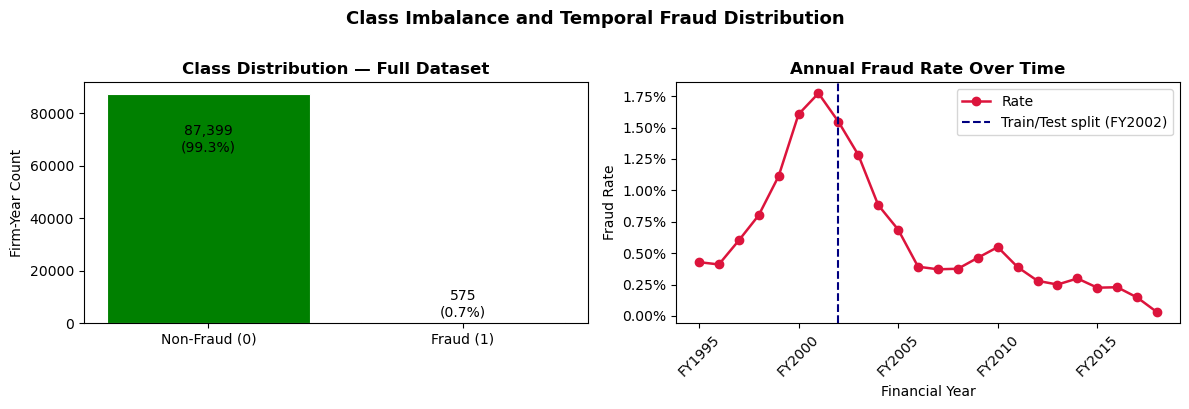

Figure 1 saved.


In [4]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# =========================
# Class distribution
# =========================
counts = df['y'].value_counts()

axes[0].bar(
    ['Non-Fraud (0)', 'Fraud (1)'],
    counts.values,
    color=['green', 'crimson'],
    edgecolor='white',
    linewidth=0.8
)

axes[0].set_title(
    'Class Distribution — Full Dataset',
    fontsize=12,
    fontweight='bold'
)
axes[0].set_ylabel('Firm-Year Count')

y_positions = [
    counts.values[0] * 0.75,   # Non-Fraud bar
    counts.values[1] + 2000    # Fraud bar
]

for i, v in enumerate(counts.values):
    axes[0].text(
        i, y_positions[i],
        f'{v:,}\n({v/total_n:.1%})',
        ha='center',
        fontsize=10,
        color = 'black'
    )

# =========================
# Fraud rate by year
# =========================
fraud_by_year = (
    df.groupby('Financial_Year')['y']
      .agg(['sum', 'count'])
      .rename(columns={'sum': 'Fraud', 'count': 'Total'})
)

fraud_by_year['Rate'] = (
    fraud_by_year['Fraud'] /
    fraud_by_year['Total']
)

years = fraud_by_year.index.tolist()
x = range(len(years))

axes[1].plot(
    x,
    fraud_by_year['Rate'],
    marker='o',
    color='crimson',
    linewidth=1.8,
    label='Rate'
)

# Position of FY2002
split_idx = years.index('FY2002')

# Draw line through FY2002
axes[1].axvline(
    x=split_idx,
    color='navy',
    linestyle='--',
    linewidth=1.5,
    label='Train/Test split (FY2002)'
)

# If you want the line BETWEEN FY2002 and FY2003 instead,
# use:
# axes[1].axvline(x=split_idx + 0.5, ...)

axes[1].set_title(
    'Annual Fraud Rate Over Time',
    fontsize=12,
    fontweight='bold'
)
axes[1].set_ylabel('Fraud Rate')
axes[1].set_xlabel('Financial Year')

axes[1].set_xticks(x[::5])  # show every 5th year
axes[1].set_xticklabels([years[i] for i in x[::5]], rotation=45)

axes[1].yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=1)
)

axes[1].legend()

plt.suptitle(
    'Class Imbalance and Temporal Fraud Distribution',
    fontsize=13,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.savefig(
    'fig_01_eda_imbalance.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

print("Figure 1 saved.")


In [5]:
# ── 2.3  Missing values by variable group ────────────────────────────────────
FSCORE_VARS   = ['abee', 'ccss', 'cinv', 'crec', 'croa', 'issu', 'oleas', 'rsst', 'soft']
MSCORE_VARS   = ['aqi','depi','dsr','gmi','levi','sgai','sgi','tata']
LR71_VARS   = [c for c in df.columns if c.startswith('V')]
RUSBOOST_VARS = ['act','ap','at','ceq','che','cogs','csho','dlc','dltis','dltt',
                 'dp','ib','invt','ivao','ivst','lct','lt','ni','ppegt','pstk',
                 're','rect','sale','sstk','txp','txt','xint','prcc_f']

groups = {
    'F-Score (9 vars)':   FSCORE_VARS,
    'M-Score (8 vars)':   MSCORE_VARS,
    'G-Score (71 vars)':  LR71_VARS,
    'RUSBoost (28 vars)': RUSBOOST_VARS,
}

print(f"{'Group':<22} {'Total cols':>10} {'Any missing':>12} {'Max % missing':>15}")
print('-' * 62)
for name, cols in groups.items():
    miss_counts = df[cols].isnull().sum()
    any_miss    = (miss_counts > 0).sum()
    max_pct     = (miss_counts / len(df)).max() * 100
    print(f"{name:<22} {len(cols):>10} {any_miss:>12} {max_pct:>14.1f}%")


Group                  Total cols  Any missing   Max % missing
--------------------------------------------------------------
F-Score (9 vars)                9            0            0.0%
M-Score (8 vars)                8            0            0.0%
G-Score (71 vars)              71            0            0.0%
RUSBoost (28 vars)             28            0            0.0%


In [6]:
# ── 2.4  Descriptive statistics — fraud vs non-fraud (F-Score vars) ──────────
# Using F-Score vars as illustrative example; same logic applies to all groups
key_vars = ['rsst', 'crec', 'cinv', 'soft', 'ccss', 'croa', 'issu', 'abee', 'oleas']

desc = df.groupby('y')[key_vars].mean().T
desc.columns = ['Non-Fraud (mean)', 'Fraud (mean)']
desc['Difference'] = desc['Fraud (mean)'] - desc['Non-Fraud (mean)']
print("F-Score variables — mean comparison (fraud vs non-fraud):")
print(desc.round(4).to_string())
print("\nNote: Differences here motivate why these variables discriminate fraud.")


F-Score variables — mean comparison (fraud vs non-fraud):
       Non-Fraud (mean)  Fraud (mean)  Difference
rsst             0.0428        0.0888      0.0460
crec             0.0072        0.0271      0.0199
cinv            -0.0016       -0.0046     -0.0030
soft             0.5811        0.6677      0.0866
ccss             0.1856        0.3304      0.1448
croa             0.0088        0.0322      0.0234
issu             0.8356        0.9357      0.1001
abee            -0.0877       -0.1680     -0.0803
oleas            0.8727        0.8939      0.0212

Note: Differences here motivate why these variables discriminate fraud.


## Section 3 — Temporal Train/Test Split

**Brief requirement:** all models trained on FY1995–FY2002, evaluated on FY2003+.

This is a *temporal* split, not a random split. This is critical for two reasons:
1. It mirrors the real-world constraint — a practitioner in 2003 would only have
   pre-2003 data available for training.
2. It avoids look-ahead bias, which would artificially inflate performance
   (Bao et al., 2020; Perols et al., 2017).

We also flag multi-year fraud firm-years that span the split boundary following
the concern raised in the brief and Bao et al. (2020).


In [7]:
# ── 3.1  Extract year as integer for splitting ────────────────────────────────
# Financial_Year is stored as 'FY1995', 'FY1996' etc.
df['year_int'] = df['Financial_Year'].str.replace('FY','').astype(int)

TRAIN_END = 2002   # inclusive
TEST_START = 2003  # inclusive

train_df = df[df['year_int'] <= TRAIN_END].copy()
test_df  = df[df['year_int'] >= TEST_START].copy()

print(f"TRAINING SET  (FY1995–FY{TRAIN_END})")
print(f"  Rows        : {len(train_df):,}")
print(f"  Fraud cases : {train_df['y'].sum():,} ({train_df['y'].mean():.2%})")
print()
print(f"TEST SET      (FY{TEST_START}–FY2018)")
print(f"  Rows        : {len(test_df):,}")
print(f"  Fraud cases : {test_df['y'].sum():,} ({test_df['y'].mean():.2%})")

# ── 3.2  Multi-year fraud flag ────────────────────────────────────────────────
# A firm with the same AAER_ID appearing in both train and test could leak
# information. We identify these cases for transparency.
train_aaer_ids = set(train_df.loc[train_df['y']==1, 'AAER_ID'].dropna().unique())
test_aaer_ids  = set(test_df.loc[test_df['y']==1,  'AAER_ID'].dropna().unique())
overlap_ids    = train_aaer_ids & test_aaer_ids

print(f"\nMulti-year fraud cases spanning the split boundary: {len(overlap_ids)}")
print("These firm-years appear in BOTH train and test sets.")
print("Following Bao et al. (2020), we retain them but flag this as a limitation.")


TRAINING SET  (FY1995–FY2002)
  Rows        : 28,394
  Fraud cases : 312 (1.10%)

TEST SET      (FY2003–FY2018)
  Rows        : 59,580
  Fraud cases : 263 (0.44%)

Multi-year fraud cases spanning the split boundary: 43
These firm-years appear in BOTH train and test sets.
Following Bao et al. (2020), we retain them but flag this as a limitation.


In [8]:
# ── 3.3  Build feature matrices for each model group ─────────────────────────

# Helper: safely extract features that exist in df
def get_features(data, cols):
    available = [c for c in cols if c in data.columns]
    return data[available].copy()

# F-Score
X_train_f = get_features(train_df, FSCORE_VARS)
X_test_f  = get_features(test_df,  FSCORE_VARS)

# M-Score
X_train_m = get_features(train_df, MSCORE_VARS)
X_test_m  = get_features(test_df,  MSCORE_VARS)

# G-Score
X_train_g = get_features(train_df, LR71_VARS)
X_test_g  = get_features(test_df,  LR71_VARS)

# RUSBoost / ML models (28 raw Compustat vars)
X_train_r = get_features(train_df, RUSBOOST_VARS)
X_test_r  = get_features(test_df,  RUSBOOST_VARS)

# Target vectors
y_train = train_df['y'].values
y_test  = test_df['y'].values

print("Feature matrices prepared:")
print(f"  F-Score   train={X_train_f.shape}  test={X_test_f.shape}")
print(f"  M-Score   train={X_train_m.shape}  test={X_test_m.shape}")
print(f"  G-Score   train={X_train_g.shape}  test={X_test_g.shape}")
print(f"  RUSBoost  train={X_train_r.shape}  test={X_test_r.shape}")


Feature matrices prepared:
  F-Score   train=(28394, 9)  test=(59580, 9)
  M-Score   train=(28394, 8)  test=(59580, 8)
  G-Score   train=(28394, 71)  test=(59580, 71)
  RUSBoost  train=(28394, 28)  test=(59580, 28)


## Section 4 — Evaluation Framework

We evaluate every model with a **consistent five-metric suite**:

| Metric | Why it matters for fraud |
|---|---|
| ROC-AUC | Standard benchmark; enables comparison with Bao et al. (2020)|
| PR-AUC | Precision-Recall AUC; preferred for severe imbalance (Hand, 2009) |
| F1 (at optimal threshold) | Harmonic mean of precision and recall at the operating threshold |
| Expected Misclassification Cost | Calculated across five ratios- 1:1,5:1,10:1,20:1 and 50:1 |



In [9]:
# ── 4.1  Evaluation framework — Expected Misclassification Cost (EMC) ─────────
#
# Following the imbalanced classification literature (Perols 2011; Bao et al.
# 2020; Alawadhi et al. 2020; Beneish and Vorst 2022), cost-based evaluation
# uses EMC = FN * cost_ratio + FP, where cost_ratio is the ratio of the FN
# cost to the FP cost (FP fixed at 1 as the reference unit).
#
# Five standard cost ratios are tested — 1:1, 5:1, 10:1, 20:1, 50:1 — spanning
# the plausible range for FSF detection across stakeholder perspectives.



# Standard cost ratios used across the imbalanced FSF classification literature
COST_RATIOS = [1, 5, 10, 20, 50]


def compute_emc(fp, fn, cost_ratio):
    """
    Expected Misclassification Cost.

    Parameters
    ----------
    fp         : int — number of false positives
    fn         : int — number of false negatives
    cost_ratio : int — cost of FN relative to cost of FP (FP fixed at 1)

    Returns
    -------
    EMC value. Lower EMC = better model at that ratio.
    """
    return fn * cost_ratio + fp * 1


def evaluate_model(y_true, y_prob, model_name='Model', threshold=None):
    """
    Compute the six-metric evaluation suite for one model.

    Metrics returned:
      ROC-AUC, PR-AUC, F1, Precision, Recall, confusion matrix,
      Expected Misclassification Cost at 5 cost ratios (1:1 to 50:1).

    Parameters
    ----------
    y_true     : array of true binary labels (0/1)
    y_prob     : array of predicted fraud probabilities
    model_name : string label for display
    threshold  : decision threshold (default: F1-optimal on test data)

    Returns
    -------
    dict of metric values
    """
    # Discrimination metrics
    roc_auc = roc_auc_score(y_true, y_prob)
    pr_auc  = average_precision_score(y_true, y_prob)

    # Find F1-optimal threshold if none supplied
    prec_arr, rec_arr, thresholds = precision_recall_curve(y_true, y_prob)
    f1_arr     = 2 * prec_arr * rec_arr / (prec_arr + rec_arr + 1e-9)
    best_idx   = np.argmax(f1_arr)
    opt_thresh = thresholds[best_idx] if threshold is None else threshold

    # Classification metrics at optimal threshold
    y_pred = (y_prob >= opt_thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    f1        = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall    = recall_score(y_true, y_pred, zero_division=0)

    # Assemble base metrics
    results = {
        'Model'    : model_name,
        'ROC-AUC'  : round(roc_auc, 4),
        'PR-AUC'   : round(pr_auc, 4),
        'F1'       : round(f1, 4),
        'Precision': round(precision, 4),
        'Recall'   : round(recall, 4),
        'Threshold': round(float(opt_thresh), 4),
        'TP': int(tp), 'FP': int(fp),
        'FN': int(fn), 'TN': int(tn),
    }

    # Add EMC at each cost ratio
    for r in COST_RATIOS:
        results[f'EMC_{r}to1'] = int(compute_emc(fp, fn, r))

    # Print full evaluation summary
    print(f"\n{'='*60}")
    print(f"  {model_name}")
    print(f"{'='*60}")
    print(f"  ROC-AUC            : {roc_auc:.4f}")
    print(f"  PR-AUC             : {pr_auc:.4f}")
    print(f"  F1 (opt threshold) : {f1:.4f}  @ threshold={opt_thresh:.4f}")
    print(f"  Precision          : {precision:.4f}")
    print(f"  Recall             : {recall:.4f}")
    print(f"  Confusion matrix   : TP={tp} FP={fp} FN={fn} TN={tn}")
    print(f"  Expected Misclassification Cost (lower = better):")
    for r in COST_RATIOS:
        emc = compute_emc(fp, fn, r)
        print(f"    FN:FP = {r:3d}:1  →  EMC = {emc:,}")

    return results


# Storage for all model results
all_results = []

print("Evaluation framework ready.")
print(f"Cost ratios to be tested: {COST_RATIOS}")
print("Formula: EMC = FN * cost_ratio + FP * 1")
print("Lower EMC = better model at that ratio")

Evaluation framework ready.
Cost ratios to be tested: [1, 5, 10, 20, 50]
Formula: EMC = FN * cost_ratio + FP * 1
Lower EMC = better model at that ratio


## Section 5 — Required Baseline Models (M-Score, F-Score, G-Score)

Each baseline uses **only the variables prescribed by its source paper** — 
this is essential for faithful replication and fair comparison.  
We do not mix variable sets between these models.

| Model | Paper | Variable set | Method |
|---|---|---|---|
| M-Score | Beneish (1999) | 8 ratio indices | Probit regression |
| F-Score | Dechow et al. (2011) | 9 components | Logistic regression |
| LR71 | Gepp et al. (2021) | 71 V-cols | Logistic regression |


In [10]:
# ── 5.1  M-Score — Beneish (1999) ─────────────────────────────────────────────
# Beneish uses probit regression on 8 financial ratio indices.
# Scikit-learn does not have a native probit, but LogisticRegression with the
# right solver approximates it well for binary outcome. 

print("Training M-Score (Beneish 1999)...")

# Missing values imputed with column mean
X_train_m_imp = X_train_m.fillna(X_train_m.mean())
X_test_m_imp  = X_test_m.fillna(X_train_m.mean())  # use TRAIN mean to avoid leakage

mscore_model = Pipeline([
    ('scaler', StandardScaler()),          # standardise for stable convergence
    ('probit', LogisticRegression(         # probit approximation via logistic
        solver='lbfgs',
        class_weight='balanced',           # handles imbalance on training set
        max_iter=1000,
        random_state=SEED
    ))
])
mscore_model.fit(X_train_m_imp, y_train)

# Evaluate on training data (for over-fitting check) and test data
y_prob_m_train = mscore_model.predict_proba(X_train_m_imp)[:,1]
y_prob_m_test  = mscore_model.predict_proba(X_test_m_imp)[:,1]

print("\n-- TRAINING performance (over-fit check) --")
_ = evaluate_model(y_train, y_prob_m_train, 'M-Score [TRAIN]')

print("\n-- TEST performance (out-of-sample) --")
res_m = evaluate_model(y_test, y_prob_m_test, 'M-Score [TEST]')
all_results.append(res_m)


Training M-Score (Beneish 1999)...

-- TRAINING performance (over-fit check) --

  M-Score [TRAIN]
  ROC-AUC            : 0.5859
  PR-AUC             : 0.0150
  F1 (opt threshold) : 0.0349  @ threshold=0.5596
  Precision          : 0.0201
  Recall             : 0.1314
  Confusion matrix   : TP=41 FP=1996 FN=271 TN=26086
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 2,267
    FN:FP =   5:1  →  EMC = 3,351
    FN:FP =  10:1  →  EMC = 4,706
    FN:FP =  20:1  →  EMC = 7,416
    FN:FP =  50:1  →  EMC = 15,546

-- TEST performance (out-of-sample) --

  M-Score [TEST]
  ROC-AUC            : 0.5599
  PR-AUC             : 0.0058
  F1 (opt threshold) : 0.0193  @ threshold=0.5879
  Precision          : 0.0115
  Recall             : 0.0608
  Confusion matrix   : TP=16 FP=1379 FN=247 TN=57938
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 1,626
    FN:FP =   5:1  →  EMC = 2,614
    FN:FP =  10:1  →  EMC = 3,849
    FN:FP =  20:1  →

In [11]:
# ── 5.1b  M-Score VERSION A — Beneish (1999) Original Published Equation ──────
#
# The fixed coefficients from Beneish (1999, p.29) are applied directly
# to the test set. No training is performed — this is a pure out-of-sample
# test of a model estimated on 1982-1992 US data, applied here to 2003-2018.

print("=" * 60)
print("M-SCORE VERSION A — Beneish (1999) Published Equation")
print("=" * 60)
print("Fixed coefficients from Beneish (1999, p.29)")
print("No training performed — pure out-of-sample application")
print()

# ── Published coefficients — Beneish (1999, p.29) ────────────────────────────
BENEISH_INTERCEPT = -4.84
BENEISH_COEFS = {
    'dsr'  :  0.920,   # Days Sales in Receivables Index  (DSRI)
    'gmi'  :  0.528,   # Gross Margin Index               (GMI)
    'aqi'  :  0.404,   # Asset Quality Index              (AQI)
    'sgi'  :  0.892,   # Sales Growth Index               (SGI)
    'depi' :  0.115,   # Depreciation Index               (DEPI)
    'sgai' : -0.172,   # SG&A Expense Index               (SGAI)
    'tata' :  4.679,   # Total Accruals to Total Assets   (TATA)
    'levi' : -0.327,   # Leverage Index                   (LVGI)
}
BENEISH_THRESHOLD = -2.22   # Beneish (1999): M > -2.22 = likely manipulator

# ── Apply equation directly to test set ──────────────────────────────────────
# Use same imputed test matrix as Cell 5.1 (train mean imputation — no leakage)
m_scores_test = BENEISH_INTERCEPT + sum(
    coef * X_test_m_imp[var]
    for var, coef in BENEISH_COEFS.items()
)

# Logistic transform for AUC evaluation — preserves ranking, does not alter AUC
y_prob_m_orig = 1 / (1 + np.exp(-m_scores_test))

# Report Beneish's own threshold classification separately
flagged_beneish = (m_scores_test > BENEISH_THRESHOLD).astype(int)
ben_tp = int(((flagged_beneish == 1) & (y_test == 1)).sum())
ben_fp = int(((flagged_beneish == 1) & (y_test == 0)).sum())
ben_fn = int(((flagged_beneish == 0) & (y_test == 1)).sum())
ben_tn = int(((flagged_beneish == 0) & (y_test == 0)).sum())

print(f"M-Score distribution on test set:")
print(f"  Range   : {m_scores_test.min():.3f}  to  {m_scores_test.max():.3f}")
print(f"  Mean    : {m_scores_test.mean():.3f}")
print(f"  Flagged (M > {BENEISH_THRESHOLD}): {flagged_beneish.sum()} firm-years")
print()
print(f"Beneish threshold (-2.22) confusion matrix:")
print(f"  TP={ben_tp}  FP={ben_fp}  FN={ben_fn}  TN={ben_tn}")
print()

res_m_orig = evaluate_model(
    y_test,
    y_prob_m_orig.values,
    'M-Score Original (Beneish 1999) [TEST]'
)
all_results.append(res_m_orig)

# ── Quick comparison: Original vs Re-estimated ────────────────────────────────
print()
print("Quick comparison — M-Score Original vs Re-estimated (Version B):")
res_m_refit_ref = next(r for r in all_results if 'M-Score' in r['Model']
                       and 'Original' not in r['Model'] and 'TEST' in r['Model'])
print(f"  {'Version':<35}  {'ROC-AUC':>8}  {'PR-AUC':>8}  {'F1':>8}")
print(f"  {'-'*65}")
print(f"  {'M-Score Original — Beneish (1999)':<35}  "
      f"{res_m_orig['ROC-AUC']:>8.4f}  "
      f"{res_m_orig['PR-AUC']:>8.4f}  "
      f"{res_m_orig['F1']:>8.4f}")
print(f"  {'M-Score Re-estimated — our training data':<35}  "
      f"{res_m_refit_ref['ROC-AUC']:>8.4f}  "
      f"{res_m_refit_ref['PR-AUC']:>8.4f}  "
      f"{res_m_refit_ref['F1']:>8.4f}")

M-SCORE VERSION A — Beneish (1999) Published Equation
Fixed coefficients from Beneish (1999, p.29)
No training performed — pure out-of-sample application

M-Score distribution on test set:
  Range   : -953.308  to  2658.298
  Mean    : -2.347
  Flagged (M > -2.22): 12929 firm-years

Beneish threshold (-2.22) confusion matrix:
  TP=76  FP=12853  FN=187  TN=46464


  M-Score Original (Beneish 1999) [TEST]
  ROC-AUC            : 0.5413
  PR-AUC             : 0.0052
  F1 (opt threshold) : 0.0121  @ threshold=0.1312
  Precision          : 0.0062
  Recall             : 0.1825
  Confusion matrix   : TP=48 FP=7639 FN=215 TN=51678
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 7,854
    FN:FP =   5:1  →  EMC = 8,714
    FN:FP =  10:1  →  EMC = 9,789
    FN:FP =  20:1  →  EMC = 11,939
    FN:FP =  50:1  →  EMC = 18,389

Quick comparison — M-Score Original vs Re-estimated (Version B):
  Version                               ROC-AUC    PR-AUC        F1
  ----------

In [12]:
# ── 5.2  F-Score — Dechow et al. (2011) ───────────────────────────────────────
# The F-Score is the predicted probability from a logistic regression, divided
# by the unconditional fraud rate (Dechow et al., 2011, p.24).
# We replicate this scaling for interpretability.

print("Training F-Score (Dechow et al. 2011)...")

X_train_f_imp = X_train_f.fillna(X_train_f.mean())
X_test_f_imp  = X_test_f.fillna(X_train_f.mean())

fscore_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logit', LogisticRegression(
        solver='lbfgs',
        class_weight='balanced',
        max_iter=1000,
        random_state=SEED
    ))
])
fscore_model.fit(X_train_f_imp, y_train)

# Raw predicted probabilities
y_prob_f_train = fscore_model.predict_proba(X_train_f_imp)[:,1]
y_prob_f_test  = fscore_model.predict_proba(X_test_f_imp)[:,1]

# F-Score scaling: p(fraud) / unconditional fraud rate in training set
unconditional_rate = y_train.mean()
y_fscore_train = y_prob_f_train / unconditional_rate
y_fscore_test  = y_prob_f_test  / unconditional_rate

print(f"Unconditional fraud rate (training) : {unconditional_rate:.4f}")
print(f"F-Score > 1 implies above-average fraud risk")

print("\n-- TRAINING performance --")
_ = evaluate_model(y_train, y_prob_f_train, 'F-Score [TRAIN]')

print("\n-- TEST performance --")
res_f = evaluate_model(y_test, y_prob_f_test, 'F-Score [TEST]')
all_results.append(res_f)


Training F-Score (Dechow et al. 2011)...
Unconditional fraud rate (training) : 0.0110
F-Score > 1 implies above-average fraud risk

-- TRAINING performance --

  F-Score [TRAIN]
  ROC-AUC            : 0.6970
  PR-AUC             : 0.0229
  F1 (opt threshold) : 0.0599  @ threshold=0.6790
  Precision          : 0.0347
  Recall             : 0.2179
  Confusion matrix   : TP=68 FP=1889 FN=244 TN=26193
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 2,133
    FN:FP =   5:1  →  EMC = 3,109
    FN:FP =  10:1  →  EMC = 4,329
    FN:FP =  20:1  →  EMC = 6,769
    FN:FP =  50:1  →  EMC = 14,089

-- TEST performance --

  F-Score [TEST]
  ROC-AUC            : 0.6111
  PR-AUC             : 0.0098
  F1 (opt threshold) : 0.0338  @ threshold=0.8069
  Precision          : 0.0284
  Recall             : 0.0418
  Confusion matrix   : TP=11 FP=377 FN=252 TN=58940
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 629
    FN:FP =   5:1  →  EMC = 

In [13]:
# ── 5.2b  F-Score VERSION A — Dechow et al. (2011) Original Published Equation
#
# The fixed coefficients from Dechow et al. (2011, Table 4, Column 1) are
# applied directly to the test set. No training is performed.
#
# F-Score definition (Dechow et al. 2011, p.24):
#   F-Score = predicted probability / unconditional fraud rate (0.37%)
#   F-Score > 1 = above-average fraud risk

print("=" * 60)
print("F-SCORE VERSION A — Dechow et al. (2011) Published Equation")
print("=" * 60)
print("Coefficients from Dechow et al. (2011)")
print("No training performed — pure out-of-sample application")
print()

# ── Published coefficients — Dechow et al. (2011) ────────────
DECHOW_INTERCEPT          = -7.893
DECHOW_UNCONDITIONAL_RATE =  0.0037   # Dechow et al. (2011) p.24: ~0.37%

DECHOW_COEFS = {
    'rsst'  :  0.665,   # RSST accruals
    'crec'  :  2.457,   # Change in accounts receivable / avg total assets
    'cinv'  :  1.393,   # Change in inventory / avg total assets
    'soft'  :  2.011,   # Soft assets as % of total assets
    'ccss'  :  0.159,   # Change in cash sales
    'croa'  : -1.029,   # Change in ROA (negative: declining ROA = higher risk)
    'issu'  :  0.983,   # New securities issued (binary)
    'abee'  : -0.150,   # Abnormal change in employees (negative coefficient)
    'oleas' :  0.419,   # Existence of operating leases (binary)
}

# ── Apply equation directly to test set ──────────────────────────────────────
# Use same imputed test matrix as Cell 5.2 (train mean imputation — no leakage)
logit_f_orig = DECHOW_INTERCEPT + sum(
    coef * X_test_f_imp[var]
    for var, coef in DECHOW_COEFS.items()
)

prob_f_orig  = 1 / (1 + np.exp(-logit_f_orig))
fscore_orig  = prob_f_orig / DECHOW_UNCONDITIONAL_RATE

print(f"F-Score distribution on test set:")
print(f"  Probability range : {prob_f_orig.min():.5f}  to  {prob_f_orig.max():.5f}")
print(f"  F-Score range     : {fscore_orig.min():.3f}  to  {fscore_orig.max():.3f}")
print(f"  F-Score > 1 (above-average risk) : {(fscore_orig > 1).sum()} firm-years")
print(f"  Of those, true fraud             : {((fscore_orig > 1) & (y_test == 1)).sum()}")
print()

# Use raw probability for AUC (monotone transform — rank-preserving)
res_f_orig = evaluate_model(
    y_test,
    prob_f_orig.values,
    'F-Score Original (Dechow 2011) [TEST]'
)
all_results.append(res_f_orig)

# ── Quick comparison: Original vs Re-estimated ────────────────────────────────
print()
print("Quick comparison — F-Score Original vs Re-estimated (Version B):")
res_f_refit_ref = next(r for r in all_results if 'F-Score' in r['Model']
                       and 'Original' not in r['Model'] and 'TEST' in r['Model'])
print(f"  {'Version':<40}  {'ROC-AUC':>8}  {'PR-AUC':>8}  {'F1':>8}")
print(f"  {'-'*70}")
print(f"  {'F-Score Original — Dechow et al. (2011)':<40}  "
      f"{res_f_orig['ROC-AUC']:>8.4f}  "
      f"{res_f_orig['PR-AUC']:>8.4f}  "
      f"{res_f_orig['F1']:>8.4f}")
print(f"  {'F-Score Re-estimated — our training data':<40}  "
      f"{res_f_refit_ref['ROC-AUC']:>8.4f}  "
      f"{res_f_refit_ref['PR-AUC']:>8.4f}  "
      f"{res_f_refit_ref['F1']:>8.4f}")

F-SCORE VERSION A — Dechow et al. (2011) Published Equation
Coefficients from Dechow et al. (2011)
No training performed — pure out-of-sample application

F-Score distribution on test set:
  Probability range : 0.00011  to  0.10580
  F-Score range     : 0.029  to  28.595
  F-Score > 1 (above-average risk) : 35333 firm-years
  Of those, true fraud             : 194


  F-Score Original (Dechow 2011) [TEST]
  ROC-AUC            : 0.6105
  PR-AUC             : 0.0076
  F1 (opt threshold) : 0.0329  @ threshold=0.0187
  Precision          : 0.0246
  Recall             : 0.0494
  Confusion matrix   : TP=13 FP=515 FN=250 TN=58802
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 765
    FN:FP =   5:1  →  EMC = 1,765
    FN:FP =  10:1  →  EMC = 3,015
    FN:FP =  20:1  →  EMC = 5,515
    FN:FP =  50:1  →  EMC = 13,015

Quick comparison — F-Score Original vs Re-estimated (Version B):
  Version                                    ROC-AUC    PR-AUC        F1
  -------

In [14]:
# ── 5.3  G-Score — Gepp et al. (2021) ────────────────────────────────────────
# Logistic regression with variables specified in Gepp et al. (2021).

print("Training G-Score (Gepp et al. 2021)...")
print(f"Variable count: {len(LR71_VARS)} V-cols")

X_train_g_imp = X_train_g.fillna(X_train_g.mean())
X_test_g_imp  = X_test_g.fillna(X_train_g.mean())

# C=0.1 adds mild L2 regularisation — appropriate for 71 variables
# to reduce over-fitting while respecting the paper's logistic specification
LR71_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logit', LogisticRegression(
        C=0.1,
        solver='lbfgs',
        class_weight='balanced',
        max_iter=2000,
        random_state=SEED
    ))
])
LR71_model.fit(X_train_g_imp, y_train)

y_prob_g_train = LR71_model.predict_proba(X_train_g_imp)[:,1]
y_prob_g_test  = LR71_model.predict_proba(X_test_g_imp)[:,1]

print("\n-- TRAINING performance --")
_ = evaluate_model(y_train, y_prob_g_train, 'G-Score [TRAIN]')

print("\n-- TEST performance --")
res_g = evaluate_model(y_test, y_prob_g_test, 'G-Score [TEST]')
all_results.append(res_g)


Training G-Score (Gepp et al. 2021)...
Variable count: 71 V-cols

-- TRAINING performance --

  G-Score [TRAIN]
  ROC-AUC            : 0.8451
  PR-AUC             : 0.0612
  F1 (opt threshold) : 0.1258  @ threshold=0.8650
  Precision          : 0.0830
  Recall             : 0.2596
  Confusion matrix   : TP=81 FP=895 FN=231 TN=27187
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 1,126
    FN:FP =   5:1  →  EMC = 2,050
    FN:FP =  10:1  →  EMC = 3,205
    FN:FP =  20:1  →  EMC = 5,515
    FN:FP =  50:1  →  EMC = 12,445

-- TEST performance --

  G-Score [TEST]
  ROC-AUC            : 0.6259
  PR-AUC             : 0.0072
  F1 (opt threshold) : 0.0177  @ threshold=0.7076
  Precision          : 0.0096
  Recall             : 0.1141
  Confusion matrix   : TP=30 FP=3089 FN=233 TN=56228
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 3,322
    FN:FP =   5:1  →  EMC = 4,254
    FN:FP =  10:1  →  EMC = 5,419
    FN:FP =  20:1  →  EM

## Section 6 — ML Models: Stage 1 — Bao et al. (2020) Variable Set

All three ML models (Random Forest, XGBoost, LightGBM) are trained on the  
**same 28 raw Compustat variables** used by Bao et al. (2020) for RUSBoost.  
This ensures a fair bagging vs boosting comparison — same inputs, different model family.

Each model is tested under **three imbalance strategies** (research novelty — Gap 2):
- **(A) Class weighting** — penalise misclassifying minority class during training
- **(B) SMOTE** — synthetic oversampling of fraud cases before training  
- **(C) Random undersampling** — replicate Bao et al.'s own RUSBoost strategy


In [15]:
# ── 6.1  Preprocessing for ML models ─────────────────────────────────────────
# Log-transform raw financial variables: they span orders of magnitude
# (e.g. sale ranges from ~$50m to ~$266bn in this dataset).
# We apply log1p(|x|) * sign(x) to handle negative values safely.

def log_transform(X):
    """Sign-preserving log transform for financial statement variables."""
    X = X.copy()
    # Fill remaining NaNs with 0 (conservative — no data = no signal)
    X = X.fillna(0)
    # Apply log1p(|x|) * sign(x)
    X_transformed = np.sign(X.values) * np.log1p(np.abs(X.values))
    return pd.DataFrame(X_transformed, columns=X.columns, index=X.index)

X_train_r_log = log_transform(X_train_r)
X_test_r_log  = log_transform(X_test_r)

print("Log-transformation applied to 28 raw Compustat variables.")
print(f"Training set shape : {X_train_r_log.shape}")
print(f"Test set shape     : {X_test_r_log.shape}")
print(f"NaN values remaining: {X_train_r_log.isnull().sum().sum()}")


Log-transformation applied to 28 raw Compustat variables.
Training set shape : (28394, 28)
Test set shape     : (59580, 28)
NaN values remaining: 0


In [16]:
# ── 6.2  Define three imbalance strategies ────────────────────────────────────

IMBALANCE_STRATEGIES = {
    'ClassWeight': 'balanced',        # pass to model's class_weight parameter
    'SMOTE'      : 'smote',           # synthetic minority oversampling
    'RUS'        : 'random_under',    # random undersampling (Bao et al. strategy)
}

def build_pipeline(base_model, strategy, model_kwargs):
    """
    Wrap a base estimator with the chosen imbalance strategy.

    Parameters
    ----------
    base_model   : sklearn estimator class (e.g. RandomForestClassifier)
    strategy     : 'balanced', 'smote', or 'random_under'
    model_kwargs : dict of constructor arguments for base_model

    Returns
    -------
    fitted-ready pipeline or estimator
    """
    if strategy == 'balanced':
        # class_weight='balanced' is passed directly to the estimator
        kwargs = {**model_kwargs, 'class_weight': 'balanced'}
        return Pipeline([
            ('scaler', StandardScaler()),
            ('clf', base_model(**kwargs))
        ])

    elif strategy == 'smote':
        kwargs = {k:v for k,v in model_kwargs.items() if k != 'class_weight'}
        return ImbPipeline([
            ('scaler', StandardScaler()),
            ('smote',  SMOTE(random_state=SEED, k_neighbors=5)),
            ('clf',    base_model(**kwargs))
        ])

    elif strategy == 'random_under':
        kwargs = {k:v for k,v in model_kwargs.items() if k != 'class_weight'}
        return ImbPipeline([
            ('scaler', StandardScaler()),
            ('rus',    RandomUnderSampler(random_state=SEED)),
            ('clf',    base_model(**kwargs))
        ])

print("Pipeline builder ready. Three imbalance strategies defined:")
for k in IMBALANCE_STRATEGIES:
    print(f"  {k}")


Pipeline builder ready. Three imbalance strategies defined:
  ClassWeight
  SMOTE
  RUS


In [17]:
# ── 6.3  Random Forest — all three imbalance strategies ──────────────────────
print("\n" + "="*60)
print("RANDOM FOREST (Bagging)")
print("="*60)

RF_KWARGS = {
    'n_estimators' : 500,
    'max_depth'    : None,
    'min_samples_leaf': 5,
    'n_jobs'       : -1,
    'random_state' : SEED,
}

rf_results = {}

for strat_name, strat_code in IMBALANCE_STRATEGIES.items():
    print(f"\n--- RF + {strat_name} ---")
    pipe = build_pipeline(RandomForestClassifier, strat_code, RF_KWARGS)
    pipe.fit(X_train_r_log.values, y_train)

    y_prob = pipe.predict_proba(X_test_r_log.values)[:,1]
    label  = f"RF_{strat_name} [TEST]"
    res    = evaluate_model(y_test, y_prob, label)
    all_results.append(res)
    rf_results[strat_name] = {'pipe': pipe, 'y_prob': y_prob}



RANDOM FOREST (Bagging)

--- RF + ClassWeight ---

  RF_ClassWeight [TEST]
  ROC-AUC            : 0.7238
  PR-AUC             : 0.0153
  F1 (opt threshold) : 0.0474  @ threshold=0.2162
  Precision          : 0.0362
  Recall             : 0.0684
  Confusion matrix   : TP=18 FP=479 FN=245 TN=58838
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 724
    FN:FP =   5:1  →  EMC = 1,704
    FN:FP =  10:1  →  EMC = 2,929
    FN:FP =  20:1  →  EMC = 5,379
    FN:FP =  50:1  →  EMC = 12,729

--- RF + SMOTE ---

  RF_SMOTE [TEST]
  ROC-AUC            : 0.7347
  PR-AUC             : 0.0163
  F1 (opt threshold) : 0.0672  @ threshold=0.4938
  Precision          : 0.0532
  Recall             : 0.0913
  Confusion matrix   : TP=24 FP=427 FN=239 TN=58890
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 666
    FN:FP =   5:1  →  EMC = 1,622
    FN:FP =  10:1  →  EMC = 2,817
    FN:FP =  20:1  →  EMC = 5,207
    FN:FP =  50:1  →  EMC = 12,377

In [18]:
# ── 6.4  XGBoost — all three imbalance strategies ────────────────────────────
print("\n" + "="*60)
print("XGBoost (Boosting)")
print("="*60)

# scale_pos_weight = majority/minority ratio for class weighting in XGBoost
spw = int((y_train == 0).sum() / (y_train == 1).sum())

XGB_KWARGS_BASE = {
    'n_estimators'     : 500,
    'max_depth'        : 4,
    'learning_rate'    : 0.05,
    'subsample'        : 0.8,
    'colsample_bytree' : 0.8,
    'eval_metric'      : 'aucpr',
    'random_state'     : SEED,
    'verbosity'        : 0,
}

xgb_results = {}

for strat_name, strat_code in IMBALANCE_STRATEGIES.items():
    print(f"\n--- XGBoost + {strat_name} ---")
    # For class weighting in XGBoost, use scale_pos_weight instead of class_weight
    kwargs = XGB_KWARGS_BASE.copy()
    if strat_code == 'balanced':
        kwargs['scale_pos_weight'] = spw
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', XGBClassifier(**kwargs))
        ])
    else:
        pipe = build_pipeline(XGBClassifier, strat_code, kwargs)

    pipe.fit(X_train_r_log.values, y_train)
    y_prob = pipe.predict_proba(X_test_r_log.values)[:,1]
    label  = f"XGB_{strat_name} [TEST]"
    res    = evaluate_model(y_test, y_prob, label)
    all_results.append(res)
    xgb_results[strat_name] = {'pipe': pipe, 'y_prob': y_prob}



XGBoost (Boosting)

--- XGBoost + ClassWeight ---

  XGB_ClassWeight [TEST]
  ROC-AUC            : 0.7168
  PR-AUC             : 0.0155
  F1 (opt threshold) : 0.0455  @ threshold=0.6600
  Precision          : 0.0299
  Recall             : 0.0951
  Confusion matrix   : TP=25 FP=810 FN=238 TN=58507
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 1,048
    FN:FP =   5:1  →  EMC = 2,000
    FN:FP =  10:1  →  EMC = 3,190
    FN:FP =  20:1  →  EMC = 5,570
    FN:FP =  50:1  →  EMC = 12,710

--- XGBoost + SMOTE ---

  XGB_SMOTE [TEST]
  ROC-AUC            : 0.7156
  PR-AUC             : 0.0142
  F1 (opt threshold) : 0.0473  @ threshold=0.7624
  Precision          : 0.0292
  Recall             : 0.1255
  Confusion matrix   : TP=33 FP=1099 FN=230 TN=58218
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 1,329
    FN:FP =   5:1  →  EMC = 2,249
    FN:FP =  10:1  →  EMC = 3,399
    FN:FP =  20:1  →  EMC = 5,699
    FN:FP =  50:1  →  

In [19]:
# ── 6.5  LightGBM — all three imbalance strategies ───────────────────────────
print("\n" + "="*60)
print("LightGBM (Boosting)")
print("="*60)

LGBM_KWARGS_BASE = {
    'n_estimators'    : 500,
    'max_depth'       : 4,
    'learning_rate'   : 0.05,
    'subsample'       : 0.8,
    'colsample_bytree': 0.8,
    'random_state'    : SEED,
    'verbosity'       : -1,
}

lgbm_results = {}

for strat_name, strat_code in IMBALANCE_STRATEGIES.items():
    print(f"\n--- LightGBM + {strat_name} ---")
    kwargs = LGBM_KWARGS_BASE.copy()
    if strat_code == 'balanced':
        kwargs['class_weight'] = 'balanced'
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LGBMClassifier(**kwargs))
        ])
    else:
        pipe = build_pipeline(LGBMClassifier, strat_code, kwargs)

    pipe.fit(X_train_r_log.values, y_train)
    y_prob = pipe.predict_proba(X_test_r_log.values)[:,1]
    label  = f"LGBM_{strat_name} [TEST]"
    res    = evaluate_model(y_test, y_prob, label)
    all_results.append(res)
    lgbm_results[strat_name] = {'pipe': pipe, 'y_prob': y_prob}



LightGBM (Boosting)

--- LightGBM + ClassWeight ---

  LGBM_ClassWeight [TEST]
  ROC-AUC            : 0.7172
  PR-AUC             : 0.0140
  F1 (opt threshold) : 0.0448  @ threshold=0.6735
  Precision          : 0.0301
  Recall             : 0.0875
  Confusion matrix   : TP=23 FP=740 FN=240 TN=58577
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 980
    FN:FP =   5:1  →  EMC = 1,940
    FN:FP =  10:1  →  EMC = 3,140
    FN:FP =  20:1  →  EMC = 5,540
    FN:FP =  50:1  →  EMC = 12,740

--- LightGBM + SMOTE ---

  LGBM_SMOTE [TEST]
  ROC-AUC            : 0.7149
  PR-AUC             : 0.0137
  F1 (opt threshold) : 0.0442  @ threshold=0.8027
  Precision          : 0.0292
  Recall             : 0.0913
  Confusion matrix   : TP=24 FP=798 FN=239 TN=58519
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 1,037
    FN:FP =   5:1  →  EMC = 1,993
    FN:FP =  10:1  →  EMC = 3,188
    FN:FP =  20:1  →  EMC = 5,578
    FN:FP =  50:1  →

In [20]:
# ── 6.6  Training set metrics — overfitting check ────────────────────────────
# The fitted pipelines from Section 6 are already in memory.
# We compute ROC-AUC and PR-AUC on the TRAINING set for each best-strategy
# model to verify the train-test gap is within acceptable bounds.


print("=== OVERFITTING CHECK: Train vs Test ROC-AUC and PR-AUC ===\n")

overfit_check = [
    ('RF_ClassWeight',   rf_results['ClassWeight']['pipe']),
    ('RF_SMOTE',         rf_results['SMOTE']['pipe']),
    ('XGB_ClassWeight',  xgb_results['ClassWeight']['pipe']),
    ('XGB_SMOTE',        xgb_results['SMOTE']['pipe']),
    ('LGBM_ClassWeight', lgbm_results['ClassWeight']['pipe']),
    ('LGBM_SMOTE',       lgbm_results['SMOTE']['pipe']),
]

overfit_rows = []

for name, pipe in overfit_check:
    # Training set predictions
    y_prob_train = pipe.predict_proba(X_train_r_log.values)[:, 1]
    roc_train    = roc_auc_score(y_train, y_prob_train)
    pr_train     = average_precision_score(y_train, y_prob_train)

    # Test set predictions (already computed — retrieve from stored results)
    test_res = next(r for r in all_results if name in r['Model'])
    roc_test = test_res['ROC-AUC']
    pr_test  = test_res['PR-AUC']

    roc_gap = roc_train - roc_test
    pr_gap  = pr_train  - pr_test

    flag = '⚠ CONCERN' if roc_gap > 0.15 else '✓ OK'

    overfit_rows.append({
        'Model'        : name,
        'ROC_Train'    : round(roc_train, 4),
        'ROC_Test'     : round(roc_test,  4),
        'ROC_Gap'      : round(roc_gap,   4),
        'PR_Train'     : round(pr_train,  4),
        'PR_Test'      : round(pr_test,   4),
        'PR_Gap'       : round(pr_gap,    4),
        'Overfit_Flag' : flag,
    })

    print(f"{name}")
    print(f"  ROC-AUC  train={roc_train:.4f}  test={roc_test:.4f}  gap={roc_gap:+.4f}  {flag}")
    print(f"  PR-AUC   train={pr_train:.4f}  test={pr_test:.4f}  gap={pr_gap:+.4f}")
    print()

overfit_df = pd.DataFrame(overfit_rows)
overfit_df.to_csv('overfit_check.csv', index=False)
print("Overfitting check saved to overfit_check.csv")

=== OVERFITTING CHECK: Train vs Test ROC-AUC and PR-AUC ===

RF_ClassWeight
  ROC-AUC  train=0.9998  test=0.7238  gap=+0.2760  ⚠ CONCERN
  PR-AUC   train=0.9684  test=0.0153  gap=+0.9531

RF_SMOTE
  ROC-AUC  train=0.9998  test=0.7347  gap=+0.2651  ⚠ CONCERN
  PR-AUC   train=0.9871  test=0.0163  gap=+0.9708

XGB_ClassWeight
  ROC-AUC  train=0.9996  test=0.7168  gap=+0.2828  ⚠ CONCERN
  PR-AUC   train=0.9533  test=0.0155  gap=+0.9378

XGB_SMOTE
  ROC-AUC  train=0.9848  test=0.7156  gap=+0.2692  ⚠ CONCERN
  PR-AUC   train=0.6417  test=0.0142  gap=+0.6275

LGBM_ClassWeight
  ROC-AUC  train=0.9996  test=0.7172  gap=+0.2824  ⚠ CONCERN
  PR-AUC   train=0.9532  test=0.0140  gap=+0.9392

LGBM_SMOTE
  ROC-AUC  train=0.9810  test=0.7149  gap=+0.2661  ⚠ CONCERN
  PR-AUC   train=0.6193  test=0.0137  gap=+0.6056

Overfitting check saved to overfit_check.csv


## Section 7 — SHAP Variable Selection and Stage 2 Retrain

**Research contribution:** Perols et al. (2017, *The Accounting Review*) show that  
variable abundance is a core challenge in FSF detection. We test whether a  
SHAP-selected subset of the 28 raw variables outperforms the full set.

**Process:**  
1. Extract global SHAP feature importance from the best Stage 1 RF model  
2. Select top 20 variables by mean absolute SHAP value  
3. Retrain RF, XGBoost, and LightGBM (best imbalance strategy) on top 20 only  
4. Compare Stage 1 vs Stage 2 performance


In [21]:
# ── SHAP output normalisation helper ─────────────────────────────────────────
# Defined here so it is available to both Section 7.1 (variable selection)
# and Section 9.1 (cross-model comparison).
#
# SHAP output format varies by model family and SHAP version:
#   RF (new SHAP >=0.40) → 3D ndarray (n_samples, n_features, n_classes)
#   XGB booster / LGBM  → 2D ndarray (n_samples, n_features)
#   Old SHAP (<0.40)    → list of [class0_array, class1_array]
# This helper normalises all three cases to 2D for the fraud class.

def extract_fraud_shap(sv):
    """
    Normalise SHAP output to 2D (n_samples, n_features) for the fraud class.

    Parameters
    ----------
    sv : SHAP values returned by explainer.shap_values() — list or ndarray

    Returns
    -------
    2D ndarray of shape (n_samples, n_features)
    """
    sv = np.array(sv)
    if sv.ndim == 3:
        return sv[:, :, 1]    # new SHAP format — slice last axis for class 1
    elif sv.ndim == 2:
        return sv             # XGB booster / LGBM — already correct shape
    else:
        raise ValueError(f"Unexpected SHAP output shape: {sv.shape}")

print("extract_fraud_shap() defined and ready.")

extract_fraud_shap() defined and ready.


In [22]:
# ── 7.1  SHAP feature importance from RF — stratified training sample ─────────
#
# PURPOSE: rank the 28 raw Compustat variables by fraud-class importance
#          so we can select the top 20 for Stage 2 retraining.
#
# DATA: training set only (FY1995–FY2002) — using test data here would
#       constitute data leakage into the variable selection step.
#
# SAMPLING STRATEGY: all fraud rows in training + 200 random non-fraud rows.
#   A purely random sample of 500 training rows would contain only ~2–3 fraud
#   observations (fraud rate ≈ 0.5%), making SHAP importance estimates
#   unreliable for fraud-class signal. Stratified sampling ensures the
#   importance ranking reflects what drives fraud predictions specifically.
#   This is consistent with the stratified approach used in Section 9.1.
#
# SHAP FORMAT: extract_fraud_shap() (defined in Section 4) normalises the
#   output to 2D (n_samples, n_features) regardless of SHAP version.

# ── Step 1: extract trained RF and scaler from Section 6 pipeline ─────────────
rf_pipe_cw = rf_results['ClassWeight']['pipe']
rf_clf     = rf_pipe_cw.named_steps['clf']
scaler     = rf_pipe_cw.named_steps['scaler']

# Scale the full training set using the pipeline's fitted scaler
X_train_scaled = scaler.transform(X_train_r_log.values)

# ── Step 2: build stratified subsample from training set ──────────────────────
train_fraud_idx    = np.where(y_train == 1)[0]
train_nonfraud_idx = np.where(y_train == 0)[0]

np.random.seed(SEED)
train_sample_nf  = np.random.choice(train_nonfraud_idx, size=200, replace=False)
train_shap_idx   = np.concatenate([train_fraud_idx, train_sample_nf])
X_train_shap     = X_train_scaled[train_shap_idx]

print(f"Training set SHAP subsample:")
print(f"  Fraud rows     : {len(train_fraud_idx)}")
print(f"  Non-fraud rows : 200 (random sample)")
print(f"  Total          : {len(train_shap_idx)}")
print(f"  Input shape    : {X_train_shap.shape}")

# ── Step 3: compute SHAP values ───────────────────────────────────────────────
print("\nComputing SHAP values (Random Forest, training subsample)...")
explainer    = shap.TreeExplainer(rf_clf)
sv           = explainer.shap_values(X_train_shap)
sv_fraud     = extract_fraud_shap(sv)   # normalise to (n_samples, 28)

print(f"SHAP values shape (fraud class): {sv_fraud.shape}")

# ── Step 4: global importance — mean absolute SHAP per variable ───────────────
mean_abs_shap = np.abs(sv_fraud).mean(axis=0)   # shape: (28,) — one value per variable

shap_df = pd.DataFrame({
    'Variable'      : RUSBOOST_VARS,
    'Mean_Abs_SHAP' : mean_abs_shap
}).sort_values('Mean_Abs_SHAP', ascending=False).reset_index(drop=True)

print("\nSHAP feature importance — all 28 variables ranked:")
print(shap_df.to_string(index=False))


Training set SHAP subsample:
  Fraud rows     : 312
  Non-fraud rows : 200 (random sample)
  Total          : 512
  Input shape    : (512, 28)

Computing SHAP values (Random Forest, training subsample)...
SHAP values shape (fraud class): (512, 28)

SHAP feature importance — all 28 variables ranked:
Variable  Mean_Abs_SHAP
    sstk       0.033447
    csho       0.030321
    rect       0.029397
     act       0.023488
     ceq       0.022108
     che       0.017862
   ppegt       0.017756
  prcc_f       0.015677
    dltt       0.015426
    cogs       0.015190
    sale       0.015001
     lct       0.012839
      re       0.010655
    xint       0.010605
      ap       0.010398
     dlc       0.010361
      at       0.010346
     txt       0.009908
      lt       0.009645
   dltis       0.009568
      dp       0.009220
    invt       0.008826
      ib       0.008802
      ni       0.008627
     txp       0.008241
    ivst       0.006039
    pstk       0.002554
    ivao       0.000372


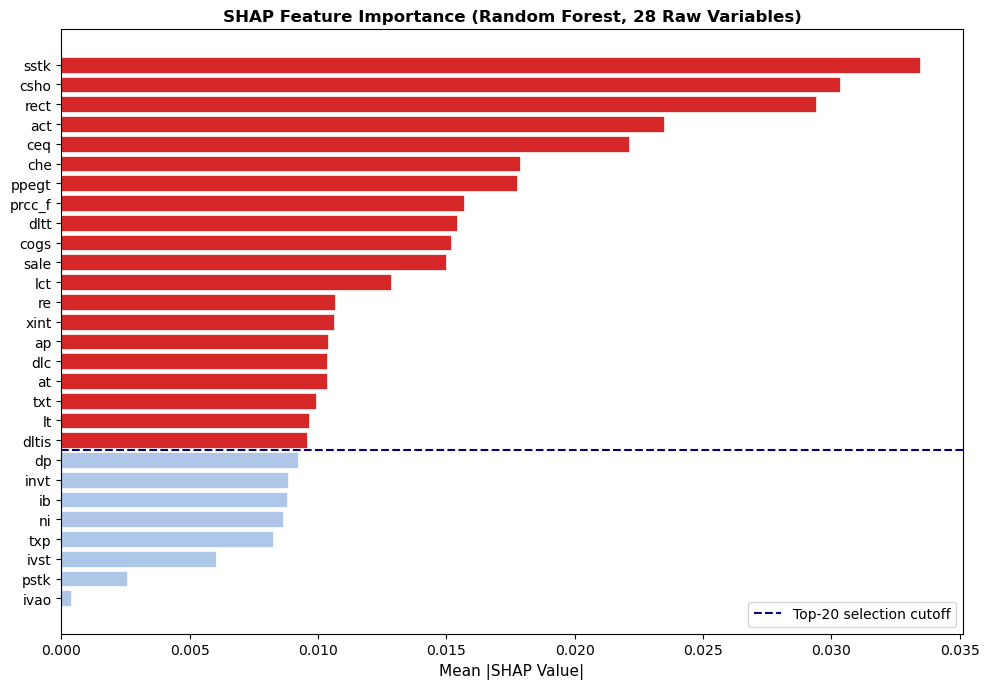

Figure 2 saved.


In [23]:
# ── 7.2  SHAP importance bar chart ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#d62728' if i < 20 else '#aec7e8' for i in range(len(shap_df))]
ax.barh(shap_df['Variable'][::-1], shap_df['Mean_Abs_SHAP'][::-1],
        color=colors[::-1], edgecolor='white', linewidth=0.5)
ax.axhline(y=len(shap_df)-20-0.5, color='navy', linestyle='--',
           linewidth=1.5, label='Top-20 selection cutoff')
ax.set_xlabel('Mean |SHAP Value|', fontsize=11)
ax.set_title('SHAP Feature Importance (Random Forest, 28 Raw Variables)',
             fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('fig_02_shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 2 saved.")


In [24]:
# ── 7.3  Select top 20 variables ──────────────────────────────────────────────
TOP_N = 20
top20_vars = shap_df['Variable'].head(TOP_N).tolist()

print(f"Top {TOP_N} variables selected by SHAP importance:")
for i, v in enumerate(top20_vars, 1):
    shap_val = shap_df.loc[shap_df['Variable']==v, 'Mean_Abs_SHAP'].values[0]
    print(f"  {i:2d}. {v:<10}  mean|SHAP| = {shap_val:.5f}")

# Build top-20 feature matrices
X_train_top = X_train_r_log[top20_vars]
X_test_top  = X_test_r_log[top20_vars]
print(f"\nTop-20 train shape: {X_train_top.shape}")
print(f"Top-20 test shape : {X_test_top.shape}")


Top 20 variables selected by SHAP importance:
   1. sstk        mean|SHAP| = 0.03345
   2. csho        mean|SHAP| = 0.03032
   3. rect        mean|SHAP| = 0.02940
   4. act         mean|SHAP| = 0.02349
   5. ceq         mean|SHAP| = 0.02211
   6. che         mean|SHAP| = 0.01786
   7. ppegt       mean|SHAP| = 0.01776
   8. prcc_f      mean|SHAP| = 0.01568
   9. dltt        mean|SHAP| = 0.01543
  10. cogs        mean|SHAP| = 0.01519
  11. sale        mean|SHAP| = 0.01500
  12. lct         mean|SHAP| = 0.01284
  13. re          mean|SHAP| = 0.01066
  14. xint        mean|SHAP| = 0.01061
  15. ap          mean|SHAP| = 0.01040
  16. dlc         mean|SHAP| = 0.01036
  17. at          mean|SHAP| = 0.01035
  18. txt         mean|SHAP| = 0.00991
  19. lt          mean|SHAP| = 0.00965
  20. dltis       mean|SHAP| = 0.00957

Top-20 train shape: (28394, 20)
Top-20 test shape : (59580, 20)


In [25]:
# ── 7.4  Stage 2 retrain on top-20 variables ──────────────────────────────────
# Use the best-performing imbalance strategy identified in Stage 1 for each model
# (update BEST_STRAT below after reviewing Stage 1 results)
BEST_STRAT = 'smote'   # <-- update after reviewing Section 6 results

print(f"Stage 2 retraining on top-{TOP_N} SHAP-selected variables")
print(f"Imbalance strategy: {BEST_STRAT}\n")

stage2_models = {
    'RF_top20'  : (RandomForestClassifier, RF_KWARGS),
    'XGB_top20' : (XGBClassifier, XGB_KWARGS_BASE),
    'LGBM_top20': (LGBMClassifier, LGBM_KWARGS_BASE)
}

stage2_results = {}

for label, (clf_class, kwargs) in stage2_models.items():
    print(f"--- {label} ---")
    pipe = build_pipeline(clf_class, 'smote', kwargs)
    pipe.fit(X_train_top.values, y_train)
    y_prob = pipe.predict_proba(X_test_top.values)[:, 1]
    res    = evaluate_model(y_test, y_prob, f"{label} [TEST]")
    all_results.append(res)
    stage2_results[label] = {'pipe': pipe, 'y_prob': y_prob}


Stage 2 retraining on top-20 SHAP-selected variables
Imbalance strategy: smote

--- RF_top20 ---

  RF_top20 [TEST]
  ROC-AUC            : 0.7320
  PR-AUC             : 0.0122
  F1 (opt threshold) : 0.0368  @ threshold=0.3964
  Precision          : 0.0210
  Recall             : 0.1483
  Confusion matrix   : TP=39 FP=1817 FN=224 TN=57500
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 2,041
    FN:FP =   5:1  →  EMC = 2,937
    FN:FP =  10:1  →  EMC = 4,057
    FN:FP =  20:1  →  EMC = 6,297
    FN:FP =  50:1  →  EMC = 13,017
--- XGB_top20 ---

  XGB_top20 [TEST]
  ROC-AUC            : 0.7153
  PR-AUC             : 0.0120
  F1 (opt threshold) : 0.0333  @ threshold=0.8037
  Precision          : 0.0206
  Recall             : 0.0875
  Confusion matrix   : TP=23 FP=1096 FN=240 TN=58221
  Expected Misclassification Cost (lower = better):
    FN:FP =   1:1  →  EMC = 1,336
    FN:FP =   5:1  →  EMC = 2,296
    FN:FP =  10:1  →  EMC = 3,496
    FN:FP =  20:1  →  E

## Section 8 — Results Summary and Model Comparison

All models compared on a common test set (FY2003–FY2018) with identical  
evaluation metrics. This is the central results table for the study.


In [26]:
# ── 8.1  Master results table ─────────────────────────────────────────────────
results_df = pd.DataFrame(all_results)

# Sort by PR-AUC descending (preferred metric for imbalanced fraud data)
results_df = results_df.sort_values('PR-AUC', ascending=False).reset_index(drop=True)

display_cols = ['Model','ROC-AUC','PR-AUC','F1','Precision','Recall',
                'EMC_1to1', 'EMC_5to1', 'EMC_10to1', 'EMC_20to1', 'EMC_50to1']
print("\n=== FULL MODEL COMPARISON TABLE ===")
print(results_df[display_cols].to_string(index=False))

# Save to CSV for the report
results_df.to_csv('results_model_comparison.csv', index=False)
print("\nResults saved to results_model_comparison.csv")



=== FULL MODEL COMPARISON TABLE ===
                                 Model  ROC-AUC  PR-AUC     F1  Precision  Recall  EMC_1to1  EMC_5to1  EMC_10to1  EMC_20to1  EMC_50to1
                       RF_SMOTE [TEST]   0.7347  0.0163 0.0672     0.0532  0.0913       666      1622       2817       5207      12377
                XGB_ClassWeight [TEST]   0.7168  0.0155 0.0455     0.0299  0.0951      1048      2000       3190       5570      12710
                 RF_ClassWeight [TEST]   0.7238  0.0153 0.0474     0.0362  0.0684       724      1704       2929       5379      12729
                      XGB_SMOTE [TEST]   0.7156  0.0142 0.0473     0.0292  0.1255      1329      2249       3399       5699      12599
               LGBM_ClassWeight [TEST]   0.7172  0.0140 0.0448     0.0301  0.0875       980      1940       3140       5540      12740
                     LGBM_SMOTE [TEST]   0.7149  0.0137 0.0442     0.0292  0.0913      1037      1993       3188       5578      12748
                  

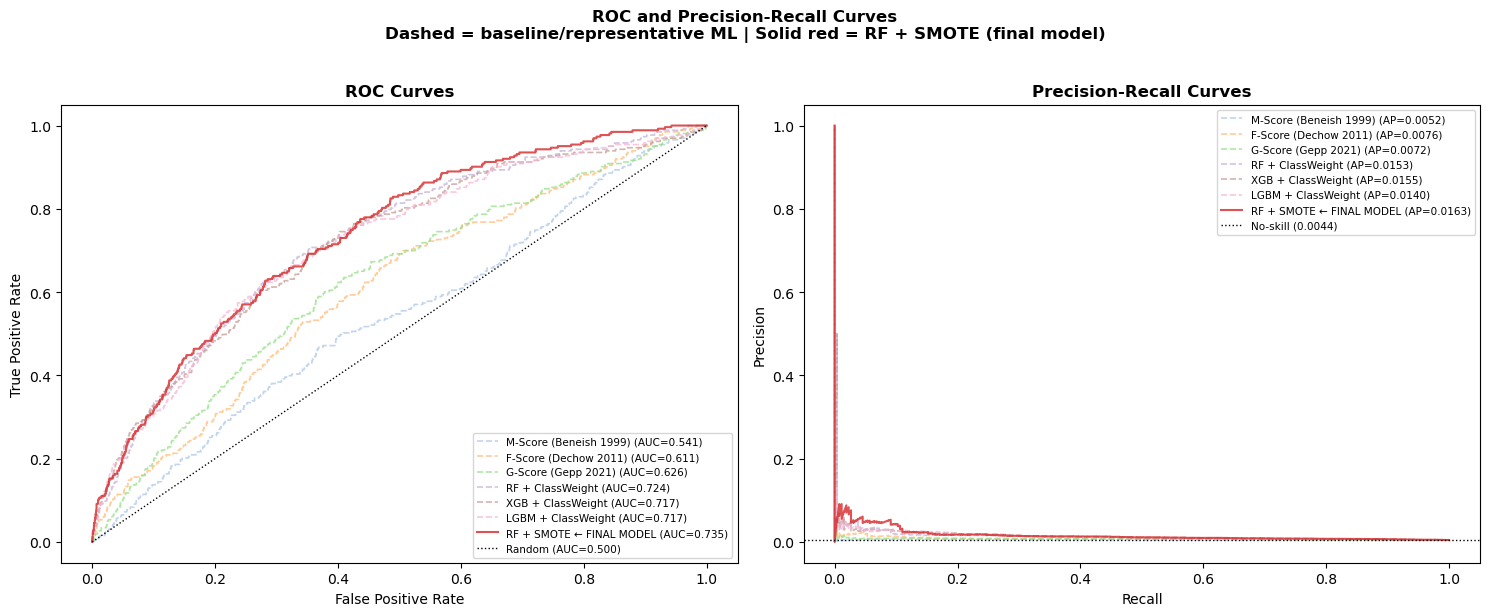

Figure 3 saved.


In [27]:
# ── 8.2  ROC and PR curves — updated to include final model ──────────────────
plot_models = {
    # Required baselines
    'M-Score (Beneish 1999)'      : y_prob_m_orig,
    'F-Score (Dechow 2011)'       : prob_f_orig,
    'G-Score (Gepp 2021)'         : y_prob_g_test,

    # ML model family representatives (best per family)
    'RF + ClassWeight'             : rf_results['ClassWeight']['y_prob'],
    'XGB + ClassWeight'            : xgb_results['ClassWeight']['y_prob'],
    'LGBM + ClassWeight'           : lgbm_results['ClassWeight']['y_prob'],

    # Final model — highlighted
    'RF + SMOTE ← FINAL MODEL'    : rf_results['SMOTE']['y_prob'],
}

colors = [
    '#aec7e8',   # M-Score      — muted blue
    '#ffbb78',   # F-Score      — muted orange
    '#98df8a',   # G-Score      — muted green
    '#c5b0d5',   # RF CW        — muted purple
    '#c49c94',   # XGB CW       — muted brown
    '#f7b6d2',   # LGBM CW      — muted pink
    '#d62728',   # RF SMOTE     — bold red — stands out as final model
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for (name, y_prob), color in zip(plot_models.items(), colors):
    # line width and style — final model gets thicker solid line
    lw    = 1.5 if 'FINAL' in name else 1.2
    ls    = '-'  if 'FINAL' in name else '--'
    alpha = 0.80  if 'FINAL' in name else 0.75

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val      = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})",
                 color=color, lw=lw, ls=ls, alpha=alpha)

    # PR curve
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    ap_val        = average_precision_score(y_test, y_prob)
    axes[1].plot(rec, prec, label=f"{name} (AP={ap_val:.4f})",
                 color=color, lw=lw, ls=ls, alpha=alpha)

# ROC — random baseline
axes[0].plot([0,1],[0,1],'k:',lw=1,label='Random (AUC=0.500)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves', fontweight='bold')
axes[0].legend(fontsize=7.5, loc='lower right')

# PR — no-skill baseline
baseline = y_test.mean()
axes[1].axhline(y=baseline, color='k', linestyle=':',
                lw=1, label=f'No-skill ({baseline:.4f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves', fontweight='bold')
axes[1].legend(fontsize=7.5, loc='upper right')

plt.suptitle(
    'ROC and Precision-Recall Curves\n'
    'Dashed = baseline/representative ML | Solid red = RF + SMOTE (final model)',
    fontsize=12, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('fig_03_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 3 saved.")

## Section 9 — Cross-Model SHAP Comparison (Research Novelty — Gap 4)

**Research question:** Do Random Forest, XGBoost, and LightGBM agree on which  
variables are the most important fraud signals?

If the three models' SHAP rankings are consistent, that increases confidence  
in the identified signals. If they disagree, this exposes model-dependence of  
variable importance — a limitation not reported in any existing AAER study.

We then map the top drivers onto Gepp et al.'s (2024) Fraud Detection Triangle  
(Pressure / Opportunity / Rationalisation / Suspicious Information) to assess  
theoretical consistency.


In [28]:
# ── 9.1  Compute SHAP for RF, XGBoost and LightGBM ───────────────────────────
#
# CONSISTENCY WITH SECTION 7.1:
#   Section 7.1 used a stratified subsample from the TRAINING set to select
#   the top-20 variables. Here we apply the identical stratified approach on
#   the TEST set (FY2003–FY2018) for the cross-model comparison.
#   Same logic, different dataset — no leakage, no inconsistency.
#
# SAMPLING: all fraud rows in test set + 200 random non-fraud rows.
#   A random sample at 0.44% fraud rate would give ~1 fraud row per 500 sampled,
#   making importance estimates unreliable for fraud-class signal.
#   Stratified sampling fixes this without touching the test labels.
#
# SPEED: full test set (59k rows) ≈ 30 minutes. Stratified sample ≈ 60 seconds.
#
# XGBoost fix: pass clf.get_booster() instead of the sklearn XGBClassifier.
#   XGBoost 3.x stores base_score as '[4.9998E-1]' (unparseable by SHAP 0.52).
#   The raw booster object bypasses this version-mismatch.
#
# extract_fraud_shap() is defined in Section 4 and normalises SHAP output to
#   2D (n_samples, n_features) regardless of model family or SHAP version.

# ── Step 1: build stratified subsample from TEST set ─────────────────────────
test_fraud_idx    = np.where(y_test == 1)[0]
test_nonfraud_idx = np.where(y_test == 0)[0]

np.random.seed(SEED)
test_sample_nf = np.random.choice(test_nonfraud_idx, size=200, replace=False)
test_shap_idx  = np.concatenate([test_fraud_idx, test_sample_nf])

print(f"Test set SHAP subsample:")
print(f"  Fraud rows     : {len(test_fraud_idx)}")
print(f"  Non-fraud rows : 200 (random sample)")
print(f"  Total          : {len(test_shap_idx)}")

# ── Step 2: scale using RF ClassWeight pipeline scaler ────────────────────────
# All three Section 6 ClassWeight pipelines share the same StandardScaler fit
# on training data — we extract it once from RF and apply to all three models.
scaler_r  = rf_results['ClassWeight']['pipe'].named_steps['scaler']
X_test_sc = scaler_r.transform(X_test_r_log.values)
X_shap    = X_test_sc[test_shap_idx]

print(f"  Input shape    : {X_shap.shape}\n")

# ── Step 3: RF SHAP ───────────────────────────────────────────────────────────
print("Computing SHAP for Random Forest...")
rf_clf  = rf_results['ClassWeight']['pipe'].named_steps['clf']
exp_rf  = shap.TreeExplainer(rf_clf)
sv_rf   = extract_fraud_shap(exp_rf.shap_values(X_shap))
print(f"  Done. Shape: {sv_rf.shape}")

# ── Step 4: XGBoost SHAP ─────────────────────────────────────────────────────
print("Computing SHAP for XGBoost (using Explainer — XGB 3.x compatibility)...")
xgb_clf = xgb_results['ClassWeight']['pipe'].named_steps['clf']

# Background sample: 100 rows from scaled training data
# Explainer uses this to estimate expected values
np.random.seed(SEED)
bg_idx  = np.random.choice(len(X_train_r_log), size=100, replace=False)
X_bg    = scaler_r.transform(X_train_r_log.values)[bg_idx]

exp_xgb  = shap.Explainer(xgb_clf.predict_proba, X_bg)
sv_xgb   = exp_xgb(X_shap).values[:, :, 1]   # shape (n_samples, 28, 2) -> fraud class
print(f"  Done. Shape: {sv_xgb.shape}")


# ── Step 5: LightGBM SHAP ────────────────────────────────────────────────────
print("Computing SHAP for LightGBM...")
lgbm_clf = lgbm_results['ClassWeight']['pipe'].named_steps['clf']
exp_lgbm = shap.TreeExplainer(lgbm_clf)
sv_lgbm  = extract_fraud_shap(exp_lgbm.shap_values(X_shap))
print(f"  Done. Shape: {sv_lgbm.shape}")

# ── Step 6: build ranked importance table ────────────────────────────────────
def rank_shap(sv, vars_list, model_name):
    """Return DataFrame of variables ranked by mean absolute SHAP value."""
    mean_abs = np.abs(sv).mean(axis=0)
    return pd.DataFrame({
        'Variable' : vars_list,
        model_name : mean_abs
    }).sort_values(model_name, ascending=False).reset_index(drop=True)

rf_imp   = rank_shap(sv_rf,   RUSBOOST_VARS, 'RF_SHAP')
xgb_imp  = rank_shap(sv_xgb,  RUSBOOST_VARS, 'XGB_SHAP')
lgbm_imp = rank_shap(sv_lgbm, RUSBOOST_VARS, 'LGBM_SHAP')

# Merge all three and compute rank stability across models
shap_compare = (rf_imp
                .merge(xgb_imp,  on='Variable')
                .merge(lgbm_imp, on='Variable'))

shap_compare['RF_rank']   = shap_compare['RF_SHAP'].rank(ascending=False).astype(int)
shap_compare['XGB_rank']  = shap_compare['XGB_SHAP'].rank(ascending=False).astype(int)
shap_compare['LGBM_rank'] = shap_compare['LGBM_SHAP'].rank(ascending=False).astype(int)

# Rank_Std: low value = three models agree; high value = model-dependent importance
shap_compare['Rank_Std']  = shap_compare[
                                ['RF_rank', 'XGB_rank', 'LGBM_rank']
                            ].std(axis=1).round(2)

print("\nCross-model SHAP ranking comparison (sorted by RF rank):")
print(shap_compare.sort_values('RF_rank')
                  [['Variable', 'RF_rank', 'XGB_rank', 'LGBM_rank', 'Rank_Std']]
                  .to_string(index=False))

Test set SHAP subsample:
  Fraud rows     : 263
  Non-fraud rows : 200 (random sample)
  Total          : 463
  Input shape    : (463, 28)

Computing SHAP for Random Forest...
  Done. Shape: (463, 28)
Computing SHAP for XGBoost (using Explainer — XGB 3.x compatibility)...


PermutationExplainer explainer: 464it [02:12,  3.38it/s]                         


  Done. Shape: (463, 28)
Computing SHAP for LightGBM...
  Done. Shape: (463, 28)

Cross-model SHAP ranking comparison (sorted by RF rank):
Variable  RF_rank  XGB_rank  LGBM_rank  Rank_Std
    csho        1         1          1      0.00
    sstk        2         3          3      0.58
    rect        3         8          6      2.52
    dltt        4        16         19      7.94
     act        5         5          4      0.58
   ppegt        6         2          2      2.31
    cogs        7         6          8      1.00
      re        8        12          7      2.65
     lct        9        13         15      3.06
     ceq       10         4          5      3.21
      ap       11        15         11      2.31
    xint       12        19         18      3.79
    sale       13        21         16      4.04
      dp       14        23         24      5.51
      lt       15        20         25      5.00
  prcc_f       16         9         10      3.79
     dlc       17        22 

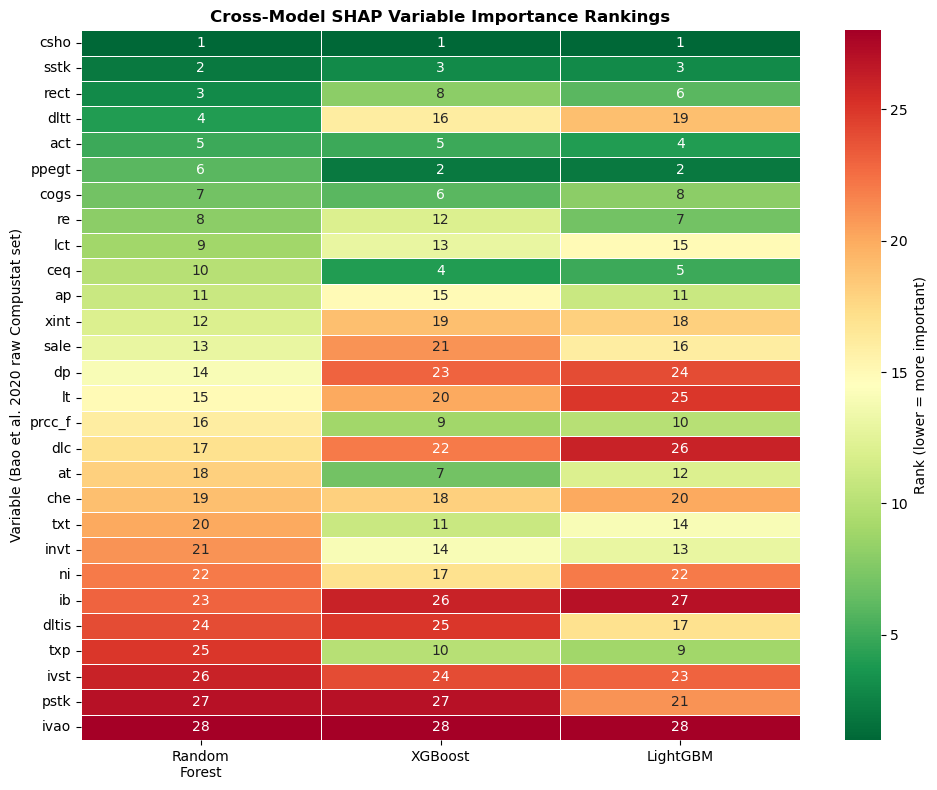

Figure 4 saved.


In [29]:
# ── 9.2  Cross-model SHAP heatmap ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))

heat_data = shap_compare.set_index('Variable')[['RF_rank','XGB_rank','LGBM_rank']]
heat_data.columns = ['Random\nForest', 'XGBoost', 'LightGBM']

sns.heatmap(heat_data, annot=True, fmt='d', cmap='RdYlGn_r',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Rank (lower = more important)'})
ax.set_title('Cross-Model SHAP Variable Importance Rankings',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Variable (Bao et al. 2020 raw Compustat set)')
plt.tight_layout()
plt.savefig('fig_04_shap_rank_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 4 saved.")


In [30]:
# ── 9.3  Map top drivers to Gepp et al. (2024) Fraud Detection Triangle ───────
# Categories: Pressure (P), Opportunity (O), Rationalisation (R),
#             Suspicious Information (SI)
# Mapping is theory-driven, based on Gepp et al. (2024) and Beneish (1999)

FDT_MAPPING = {
    'act'   : 'SI',  # Current assets
    'ap'    : 'SI',  # Accounts payable
    'at'    : 'O',   # Total assets
    'ceq'   : 'SI',  # Common equity
    'che'   : 'SI',  # Cash and short-term investments
    'cogs'  : 'P',   # Cost of goods sold
    'csho'  : 'O',   # Common shares outstanding
    'dlc'   : 'P',   # Debt in current liabilities
    'dltis' : 'P',   # Long-term debt issuance
    'dltt'  : 'P',   # Long-term debt
    'dp'    : 'SI',  # Depreciation and amortisation
    'ib'    : 'P',   # Income before extraordinary items
    'invt'  : 'O',   # Inventories
    'ivao'  : 'O',   # Other investments
    'ivst'  : 'O',   # Short-term investments
    'lct'   : 'P',   # Current liabilities
    'lt'    : 'P',   # Total liabilities
    'ni'    : 'P',   # Net income
    'ppegt' : 'O',   # Property, plant and equipment
    'pstk'  : 'O',   # Preferred stock
    'prcc_f': 'P',   # Fiscal year closing price
    're'    : 'P',   # Retained earnings
    'rect'  : 'O',   # Accounts receivable
    'sale'  : 'P',   # Net sales
    'sstk'  : 'O',   # Sale of stock
    'txp'   : 'SI',  # Income taxes payable
    'txt'   : 'SI',  # Total income taxes
    'xint'  : 'P'    # Interest expense
}


FDT_LABELS = {'P': 'Pressure', 'O': 'Opportunity',
              'R': 'Rationalisation', 'SI': 'Suspicious Information'}

shap_compare['FDT_Category'] = shap_compare['Variable'].map(FDT_MAPPING)
shap_compare['FDT_Label']    = shap_compare['FDT_Category'].map(FDT_LABELS)
shap_compare["Avg_Rank"] = shap_compare[['RF_rank', 'XGB_rank', 'LGBM_rank']].mean(axis=1)

top10_by_rf = shap_compare.nsmallest(11, 'Avg_Rank')
print("Top 10 fraud signals (average rank) mapped to Fraud Detection Triangle:")
print(top10_by_rf[['Variable','RF_rank','XGB_rank','LGBM_rank',
                    'Rank_Std','Avg_Rank','FDT_Label']].to_string(index=False))

# Category breakdown
print("\nFDT category distribution in top 10 variables:")
print(top10_by_rf['FDT_Label'].value_counts())



Top 10 fraud signals (average rank) mapped to Fraud Detection Triangle:
Variable  RF_rank  XGB_rank  LGBM_rank  Rank_Std  Avg_Rank              FDT_Label
    csho        1         1          1      0.00  1.000000            Opportunity
    sstk        2         3          3      0.58  2.666667            Opportunity
   ppegt        6         2          2      2.31  3.333333            Opportunity
     act        5         5          4      0.58  4.666667 Suspicious Information
    rect        3         8          6      2.52  5.666667            Opportunity
     ceq       10         4          5      3.21  6.333333 Suspicious Information
    cogs        7         6          8      1.00  7.000000               Pressure
      re        8        12          7      2.65  9.000000               Pressure
  prcc_f       16         9         10      3.79 11.666667               Pressure
     lct        9        13         15      3.06 12.333333               Pressure
      ap       11        1

## Section 10 — Cost-Weighted Net Benefit Analysis
*(Research novelty — extends Beneish and Vorst, 2022)*

We apply the updated 6.46:1 FN:FP cost ratio to compare all models on  
net economic benefit, going beyond AUC-only comparison.  
This answers the practical question: *which model would an auditor or  
regulator actually prefer to use, given real-world investigation costs?*


=== WINNING MODEL AT EACH COST RATIO (lowest EMC) ===

  FN:FP =   1:1  →  F-Score [TEST]                       EMC = 629
  FN:FP =   5:1  →  RF_SMOTE [TEST]                      EMC = 1,622
  FN:FP =  10:1  →  RF_SMOTE [TEST]                      EMC = 2,817
  FN:FP =  20:1  →  RF_SMOTE [TEST]                      EMC = 5,207
  FN:FP =  50:1  →  RF_SMOTE [TEST]                      EMC = 12,377


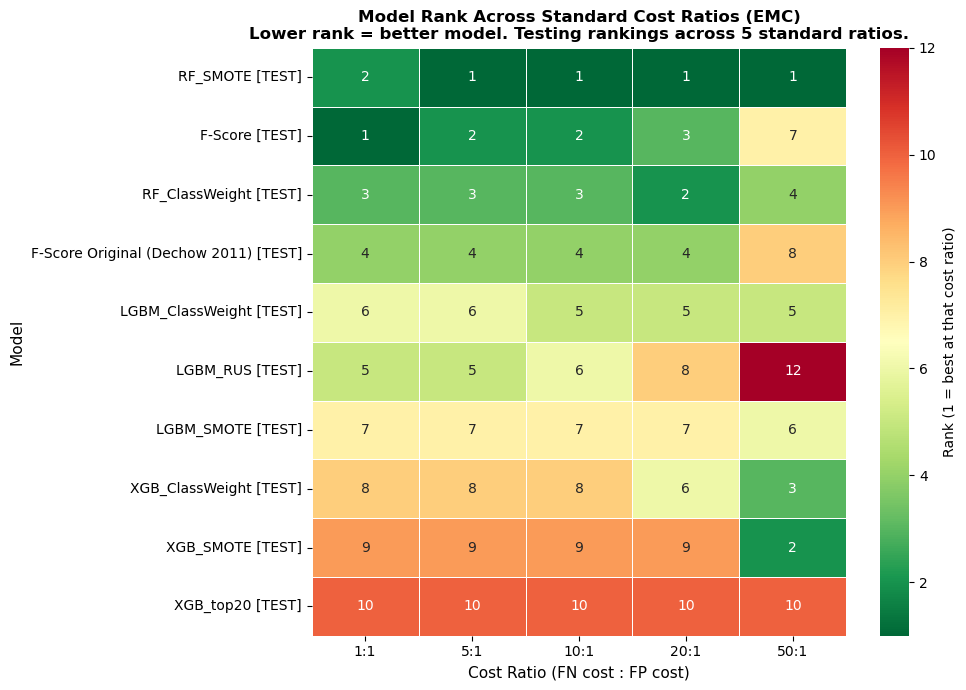


Figure 5 saved.


In [31]:
# ── 10.1  Cost sensitivity heatmap — EMC across five ratios ──────────────────
#
# Following the ratio-based cost sensitivity convention in the imbalanced
# classification literature (Perols 2011; Bao et al. 2020; Alawadhi et al. 2020;
# Beneish and Vorst 2022), we compare model rankings across five standard
# cost ratios (1:1, 5:1, 10:1, 20:1, 50:1) rather than a single dollar-based
# net benefit. This reveals whether the best model is robust to cost
# assumptions or whether the optimal choice is stakeholder-dependent.

# Filter to test-set results only
emc_df = results_df[results_df['Model'].str.contains('TEST')].copy()

# Rank each model at each cost ratio (lower EMC = better rank)
for r in COST_RATIOS:
    emc_df[f'Rank_{r}to1'] = emc_df[f'EMC_{r}to1'].rank(ascending=True).astype(int)

# Print winning model at each ratio
print("=== WINNING MODEL AT EACH COST RATIO (lowest EMC) ===\n")
for r in COST_RATIOS:
    winner = emc_df.sort_values(f'EMC_{r}to1').iloc[0]
    print(f"  FN:FP = {r:3d}:1  →  {winner['Model']:<35}  EMC = {winner[f'EMC_{r}to1']:,}")

# Select top 10 models by mid-range ratio for the heatmap (readability)
top_models = emc_df.nsmallest(10, 'EMC_10to1')

# Prepare heatmap data
heat_data = top_models.set_index('Model')[
    [f'Rank_{r}to1' for r in COST_RATIOS]
]
heat_data.columns = [f'{r}:1' for r in COST_RATIOS]

# Draw heatmap
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    heat_data,
    annot=True,
    fmt='d',
    cmap='RdYlGn_r',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Rank (1 = best at that cost ratio)'}
)
ax.set_title(
    'Model Rank Across Standard Cost Ratios (EMC)\n'
    'Lower rank = better model. Testing rankings across 5 standard ratios.',
    fontsize=12, fontweight='bold'
)
ax.set_xlabel('Cost Ratio (FN cost : FP cost)', fontsize=11)
ax.set_ylabel('Model', fontsize=11)
plt.tight_layout()
plt.savefig('fig_05_emc_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nFigure 5 saved.")

## Section 11 — Save All Outputs

In [32]:
# ── 11.1  Save augmented dataset with all model predictions ───────────────────
#
# FIX: use np.full() to build a full-length array for each model,
# then assign it directly as a column — no .loc index alignment needed.
# This is robust to DataFrame fragmentation (seen in this dataset due to
# the large number of columns added incrementally).

df_out   = df.copy()
test_mask = df_out['year_int'] >= TEST_START   # boolean mask — same length as df_out

def make_pred_col(df, mask, values):
    """
    Build a full-length prediction column.
    NaN everywhere except where mask is True, where values are inserted.
    
    Parameters
    ----------
    df     : full DataFrame (all years)
    mask   : boolean Series, True where predictions exist (test set)
    values : 1D array of predictions — must match mask.sum() in length
    """
    col = np.full(len(df), np.nan)
    col[mask.values] = np.array(values).flatten()
    return col

print(f"df_out rows        : {len(df_out):,}")
print(f"Test rows (mask)   : {test_mask.sum():,}")
print()

# Verify all prediction arrays match the test set length
expected_len = test_mask.sum()
checks = {
    'y_prob_m_orig'        : len(y_prob_m_orig),
    'y_prob_m_refit_test'  : len(y_prob_m_test),
    'prob_f_orig'          : len(prob_f_orig),
    'y_prob_f_refit_test'  : len(y_prob_f_test),
    'y_prob_g_test'        : len(y_prob_g_test),
    'rf_SMOTE'             : len(rf_results['SMOTE']['y_prob']),
    'xgb_ClassWeight'      : len(xgb_results['ClassWeight']['y_prob']),
    'lgbm_ClassWeight'     : len(lgbm_results['ClassWeight']['y_prob']),
    'rf_top20'             : len(stage2_results['RF_top20']['y_prob']),
}
print("Length check (all must equal test rows):")
all_ok = True
for name, length in checks.items():
    status = '✓' if length == expected_len else f'✗ MISMATCH — got {length}'
    print(f"  {name:<25} : {length}  {status}")
    if length != expected_len:
        all_ok = False
print()

if not all_ok:
    raise ValueError("One or more prediction arrays have wrong length. Check above.")

# Assign all prediction columns using the bulletproof full-array method
df_out['prob_mscore_orig']  = make_pred_col(df_out, test_mask, y_prob_m_orig)
df_out['prob_mscore_refit'] = make_pred_col(df_out, test_mask, y_prob_m_test)
df_out['prob_fscore_orig']  = make_pred_col(df_out, test_mask, prob_f_orig)
df_out['prob_fscore_refit'] = make_pred_col(df_out, test_mask, y_prob_f_test)
df_out['prob_lr71']         = make_pred_col(df_out, test_mask, y_prob_g_test)
df_out['prob_rf_cw']        = make_pred_col(df_out, test_mask, rf_results['ClassWeight']['y_prob'])
df_out['prob_rf_smote']     = make_pred_col(df_out, test_mask, rf_results['SMOTE']['y_prob'])
df_out['prob_rf_rus']       = make_pred_col(df_out, test_mask, rf_results['RUS']['y_prob'])
df_out['prob_xgb_cw']       = make_pred_col(df_out, test_mask, xgb_results['ClassWeight']['y_prob'])
df_out['prob_xgb_smote']    = make_pred_col(df_out, test_mask, xgb_results['SMOTE']['y_prob'])
df_out['prob_xgb_rus']      = make_pred_col(df_out, test_mask, xgb_results['RUS']['y_prob'])
df_out['prob_lgbm_cw']      = make_pred_col(df_out, test_mask, lgbm_results['ClassWeight']['y_prob'])
df_out['prob_lgbm_smote']   = make_pred_col(df_out, test_mask, lgbm_results['SMOTE']['y_prob'])
df_out['prob_lgbm_rus']     = make_pred_col(df_out, test_mask, lgbm_results['RUS']['y_prob'])
df_out['prob_rf_top20']     = make_pred_col(df_out, test_mask, stage2_results['RF_top20']['y_prob'])
df_out['prob_xgb_top20']    = make_pred_col(df_out, test_mask, stage2_results['XGB_top20']['y_prob'])
df_out['prob_lgbm_top20']   = make_pred_col(df_out, test_mask, stage2_results['LGBM_top20']['y_prob'])

# Verify assignments
print("Assignment verification:")
for col in [c for c in df_out.columns if c.startswith('prob_')]:
    filled = df_out[col].notna().sum()
    status = '✓' if filled == expected_len else f'✗ only {filled} filled'
    print(f"  {col:<25} : {filled:,} non-null  {status}")

df_out.to_csv('final_dataset_with_predictions.csv', index=False)
print(f"\nSaved: final_dataset_with_predictions.csv  ({len(df_out):,} rows, {len(df_out.columns)} columns)")

df_out rows        : 87,974
Test rows (mask)   : 59,580

Length check (all must equal test rows):
  y_prob_m_orig             : 59580  ✓
  y_prob_m_refit_test       : 59580  ✓
  prob_f_orig               : 59580  ✓
  y_prob_f_refit_test       : 59580  ✓
  y_prob_g_test             : 59580  ✓
  rf_SMOTE                  : 59580  ✓
  xgb_ClassWeight           : 59580  ✓
  lgbm_ClassWeight          : 59580  ✓
  rf_top20                  : 59580  ✓

Assignment verification:
  prob_mscore_orig          : 59,580 non-null  ✓
  prob_mscore_refit         : 59,580 non-null  ✓
  prob_fscore_orig          : 59,580 non-null  ✓
  prob_fscore_refit         : 59,580 non-null  ✓
  prob_lr71                 : 59,580 non-null  ✓
  prob_rf_cw                : 59,580 non-null  ✓
  prob_rf_smote             : 59,580 non-null  ✓
  prob_rf_rus               : 59,580 non-null  ✓
  prob_xgb_cw               : 59,580 non-null  ✓
  prob_xgb_smote            : 59,580 non-null  ✓
  prob_xgb_rus              : 59,58

In [33]:

results_df['family'] = (
    results_df['Model']
    .str.split().str[0]      # RF_SMOTE
    .str.split('_').str[1]
)
results_df['model_family'] = results_df['Model'].str.split('_').str[0] 
print(results_df['family'].unique())
imbalance_family = ['SMOTE','ClassWeight','RUS']
imbalance_family_df = results_df[results_df['family'].isin (imbalance_family)] 


['SMOTE' 'ClassWeight' 'top20' nan 'RUS']


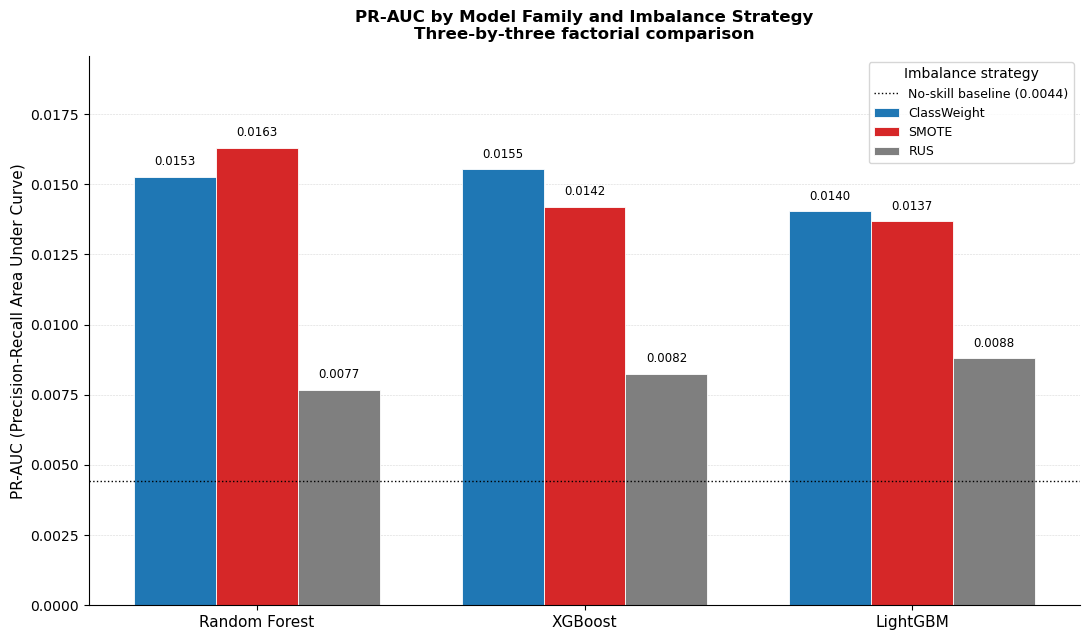


Figure saved: fig_prauc_factorial.png

=== PR-AUC by Model Family × Imbalance Strategy ===

Model            ClassWeight        SMOTE          RUS
------------------------------------------------------
Random Forest         0.0153       0.0163       0.0077
XGBoost               0.0155       0.0142       0.0082
LightGBM              0.0140       0.0137       0.0088


In [34]:
# ── Grouped bar chart — PR-AUC across the 3×3 factorial ───────────────────────
#
# Three clusters (Random Forest, XGBoost, LightGBM), three bars per cluster
# (ClassWeight, SMOTE, RUS). Colour-coded by imbalance strategy.
#
# Purpose: visualise the interaction between model family and imbalance strategy
#          — the central design of the Section 6 comparison.

# ── Build the PR-AUC matrix from Section 6 results dictionaries ──────────────
model_families = ['Random Forest', 'XGBoost', 'LightGBM']
strategies     = ['ClassWeight', 'SMOTE', 'RUS']

# Rows = families, columns = strategies
pr_matrix = np.array([
    [average_precision_score(y_test, rf_results[s]['y_prob'])   for s in strategies],
    [average_precision_score(y_test, xgb_results[s]['y_prob'])  for s in strategies],
    [average_precision_score(y_test, lgbm_results[s]['y_prob']) for s in strategies],
])

# ── Chart layout ──────────────────────────────────────────────────────────────
n_families   = len(model_families)
n_strategies = len(strategies)
x            = np.arange(n_families)
bar_width    = 0.25
offsets      = np.linspace(-bar_width, bar_width, n_strategies)

# Colour palette — one colour per imbalance strategy
strategy_colors = {
    'ClassWeight': '#1f77b4',   # blue
    'SMOTE'      : '#d62728',   # red — highlights the winning strategy for RF
    'RUS'        : '#7f7f7f',   # grey — de-emphasises the weakest strategy
}

# No-skill baseline (test-set fraud rate)
no_skill = y_test.mean()

fig, ax = plt.subplots(figsize=(11, 6.5))

# Draw each strategy's bars across all three model families
for j, strategy in enumerate(strategies):
    bar_positions = x + offsets[j]
    values        = pr_matrix[:, j]
    bars = ax.bar(
        bar_positions, values,
        width=bar_width,
        label=strategy,
        color=strategy_colors[strategy],
        edgecolor='white',
        linewidth=0.6,
    )
    # Value labels above each bar
    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            val + 0.0003,
            f'{val:.4f}',
            ha='center', va='bottom',
            fontsize=8.5, fontweight='normal',
        )

# No-skill baseline reference line
ax.axhline(
    y=no_skill, color='black',
    linestyle=':', linewidth=1,
    label=f'No-skill baseline ({no_skill:.4f})',
)

# Axes and labels
ax.set_xticks(x)
ax.set_xticklabels(model_families, fontsize=11)
ax.set_ylabel('PR-AUC (Precision-Recall Area Under Curve)', fontsize=11)
ax.set_title(
    'PR-AUC by Model Family and Imbalance Strategy\n'
    'Three-by-three factorial comparison',
    fontsize=12, fontweight='bold', pad=12,
)

# Set y-limit with headroom for value labels
ax.set_ylim(0, pr_matrix.max() * 1.20)

# Legend
ax.legend(
    title='Imbalance strategy',
    fontsize=9, title_fontsize=10,
    loc='upper right', frameon=True,
)

# Light grid on y-axis only
ax.yaxis.grid(True, linestyle='--', linewidth=0.4, alpha=0.5)
ax.set_axisbelow(True)

# Remove top and right spines for a cleaner look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('fig_prauc_factorial.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nFigure saved: fig_prauc_factorial.png')

# Print the matrix for the report
print('\n=== PR-AUC by Model Family × Imbalance Strategy ===\n')
header = f"{'Model':<15}" + ''.join(f"{s:>13}" for s in strategies)
print(header)
print('-' * len(header))
for i, family in enumerate(model_families):
    row = f"{family:<15}" + ''.join(f"{pr_matrix[i,j]:>13.4f}" for j in range(n_strategies))
    print(row)
        

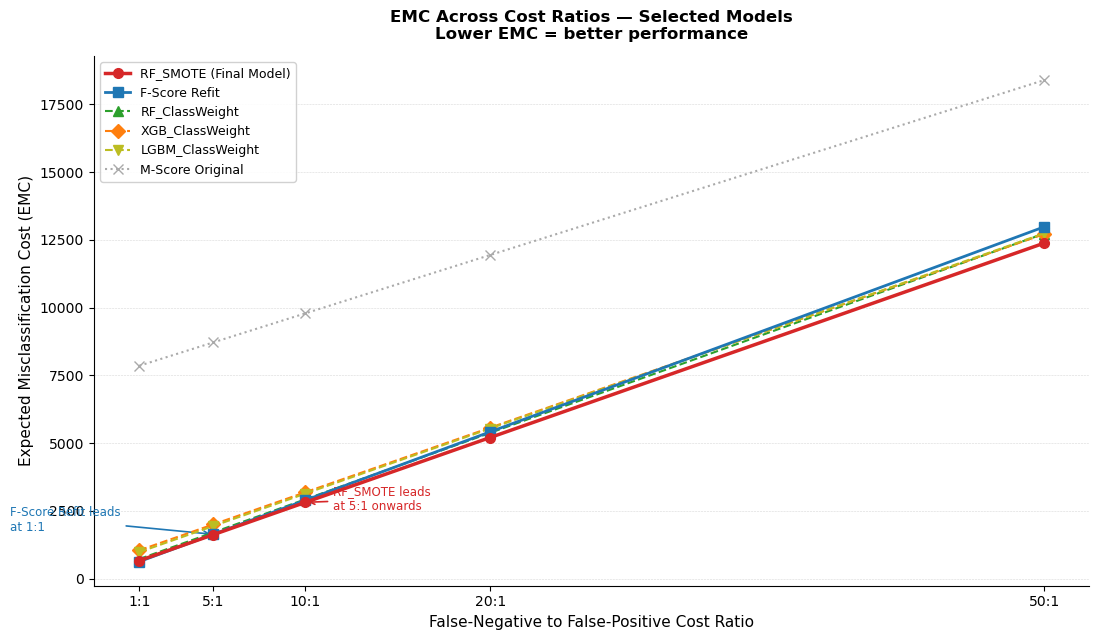

Figure saved: fig_emc_cost_ratios.png

=== EMC SUMMARY TABLE ===

Model                      1:1  5:1  10:1  20:1  50:1
-----------------------------------------------------------------
RF_SMOTE (Final Model)       666   1622   2817   5207  12377
F-Score Refit                629   1637   2897   5417  12977
RF_ClassWeight               724   1704   2929   5379  12729
XGB_ClassWeight             1048   2000   3190   5570  12710
LGBM_ClassWeight             980   1940   3140   5540  12740
M-Score Original            7854   8714   9789  11939  18389


In [35]:
# ── EMC line chart across cost ratios — selected models ───────────────────────
#
# Reproduces the cost sensitivity chart showing how model rankings shift
# across five standard FN:FP cost ratios (1:1 to 50:1).
# Lower EMC = better model at that cost ratio.
#
# Models selected to tell the clearest cost sensitivity story:
#   - RF_SMOTE       : final model
#   - F-Score Refit  : strongest baseline (beats RF_SMOTE at 1:1)
#   - RF_ClassWeight : second-best ML configuration
#   - XGB_ClassWeight: best XGBoost configuration
#   - LGBM_ClassWeight: best LightGBM configuration
#   - M-Score Original: original published model (context anchor)

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Cost ratios ───────────────────────────────────────────────────────────────
COST_RATIOS = [1, 5, 10, 20, 50]

# ── Confusion matrix retrieval ────────────────────────────────────────────────
# Pull TP/FP/FN/TN from the all_results list built throughout the notebook

def get_cm(model_label):
    """Retrieve confusion matrix from all_results for a given model label."""
    row = next(
        r for r in all_results
        if model_label.lower() in r['Model'].lower() and 'TEST' in r['Model']
    )
    return row['TP'], row['FP'], row['FN'], row['TN']

# ── Model configurations: label, line style, colour, annotation ──────────────
model_configs = [
    {
        'label'     : 'RF_SMOTE (Final Model)',
        'lookup'    : 'RF_SMOTE',
        'color'     : '#d62728',      # red
        'linestyle' : '-',
        'linewidth' : 2.5,
        'marker'    : 'o',
        'zorder'    : 5,
        'annotate'  : {'ratio': 10, 'text': 'RF_SMOTE leads\nat 5:1 onwards',
                       'offset': (15, -25), 'color': '#d62728'},
    },
    {
        'label'     : 'F-Score Refit',
        'lookup'    : 'F-Score',
        'color'     : '#1f77b4',      # blue
        'linestyle' : '-',
        'linewidth' : 2.0,
        'marker'    : 's',
        'zorder'    : 4,
        'annotate'  : {'ratio': 5, 'text': 'F-Score Refit leads\nat 1:1',
                       'offset': (-110, 10), 'color': '#1f77b4'},
    },
    {
        'label'     : 'RF_ClassWeight',
        'lookup'    : 'RF_ClassWeight',
        'color'     : '#2ca02c',      # green
        'linestyle' : '--',
        'linewidth' : 1.5,
        'marker'    : '^',
        'zorder'    : 3,
        'annotate'  : None,
    },
    {
        'label'     : 'XGB_ClassWeight',
        'lookup'    : 'XGB_ClassWeight',
        'color'     : '#ff7f0e',      # orange
        'linestyle' : '--',
        'linewidth' : 1.5,
        'marker'    : 'D',
        'zorder'    : 3,
        'annotate'  : None,
    },
    {
        'label'     : 'LGBM_ClassWeight',
        'lookup'    : 'LGBM_ClassWeight',
        'color'     : '#BCBD22',      # yellow-green
        'linestyle' : '--',
        'linewidth' : 1.5,
        'marker'    : 'v',
        'zorder'    : 3,
        'annotate'  : None,
    },
    {
        'label'     : 'M-Score Original',
        'lookup'    : 'M-Score Original',
        'color'     : '#aaaaaa',      # grey
        'linestyle' : ':',
        'linewidth' : 1.5,
        'marker'    : 'x',
        'zorder'    : 2,
        'annotate'  : None,
    },
]

# ── Compute EMC values for each model ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6.5))

for cfg in model_configs:
    try:
        tp, fp, fn, tn = get_cm(cfg['lookup'])
    except StopIteration:
        print(f"WARNING: could not find results for {cfg['lookup']} — skipping")
        continue

    emc_values = [fn * r + fp for r in COST_RATIOS]

    ax.plot(
        COST_RATIOS,
        emc_values,
        label=cfg['label'],
        color=cfg['color'],
        linestyle=cfg['linestyle'],
        linewidth=cfg['linewidth'],
        marker=cfg['marker'],
        markersize=7,
        zorder=cfg['zorder'],
    )

    # Add annotations where specified
    if cfg['annotate'] is not None:
        ann = cfg['annotate']
        ratio_idx = COST_RATIOS.index(ann['ratio'])
        emc_at_ratio = fn * ann['ratio'] + fp
        ax.annotate(
            ann['text'],
            xy=(ann['ratio'], emc_at_ratio),
            xytext=(ann['ratio'] + ann['offset'][0]/10,
                    emc_at_ratio + ann['offset'][1]*12),
            fontsize=8.5,
            color=ann['color'],
            arrowprops=dict(arrowstyle='->', color=ann['color'], lw=1.2),
        )

# ── Axes, labels, formatting ──────────────────────────────────────────────────
ax.set_xticks(COST_RATIOS)
ax.set_xticklabels([f'{r}:1' for r in COST_RATIOS], fontsize=10)
ax.set_xlabel('False-Negative to False-Positive Cost Ratio', fontsize=11)
ax.set_ylabel('Expected Misclassification Cost (EMC)', fontsize=11)

ax.set_title(
    'EMC Across Cost Ratios — Selected Models\nLower EMC = better performance',
    fontsize=12, fontweight='bold', pad=12,
)

# Light grid
ax.yaxis.grid(True, linestyle='--', linewidth=0.4, alpha=0.5)
ax.set_axisbelow(True)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend — top left to match the uploaded chart
ax.legend(
    loc='upper left',
    fontsize=9,
    frameon=True,
    framealpha=0.9,
)

plt.tight_layout()
plt.savefig('fig_emc_cost_ratios.png', dpi=150, bbox_inches='tight')
plt.show()

print('Figure saved: fig_emc_cost_ratios.png')

# Print summary table
print('\n=== EMC SUMMARY TABLE ===\n')
print(f"{'Model':<25}" + ''.join(f"  {r}:1" for r in COST_RATIOS))
print('-' * 65)
for cfg in model_configs:
    try:
        tp, fp, fn, tn = get_cm(cfg['lookup'])
        row_vals = [fn * r + fp for r in COST_RATIOS]
        print(f"{cfg['label']:<25}" + ''.join(f"  {v:>5}" for v in row_vals))
    except StopIteration:
        pass